#**Description**

This dataset contains physiological recordings and extracted features collected from 29 participants equipped with the Empatica E4 wristband during controlled laboratory stress-induction protocols. The protocol combines cognitive, social, and physical stressors across five distinct tasks (Lego assembly under varying constraints, mental arithmetic countdown, and an oral presentation) interleaved with rest/baseline recovery periods. The signals comprise Blood Volume Pulse (BVP from photoplethysmography) and Electrodermal Activity (EDA), segmented into 1-minute intervals. The processed feature set consists of 27 time-, frequency-, and non-linear domain features (16 PPG/PRV features and 11 EDA/SCR metrics) labeled for binary stress classification (0 = Rest, 1 = Stress).

#**Loading the dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import find_peaks

# Folder that contains subject_01, subject_02, ... (or its parent: "Subjects/" is auto-detected)
DATA_ROOT = "/content/drive/MyDrive/licenta/EmpaticaE4Stress/dataset"

SENSORS = ["BVP", "EDA", "TEMP", "ACC", "HR", "IBI"]
NOMINAL_FS = {"BVP": 64, "EDA": 4, "TEMP": 4, "ACC": 32, "HR": 1}
CONTINUOUS = ["BVP", "EDA", "TEMP", "ACC"]

# Protocol from paper Fig. 1: (name, duration_sec, label)  label 0 = rest, 1 = task
PROTOCOL_HEAD = [("Rest 1", 180, 0), ("Task 1", 600, 1), ("Rest 2", 120, 0), ("Task 2", 300, 1),
                 ("Rest 3", 120, 0), ("Task 3", 180, 1), ("Rest 4", 120, 0)]
# Task 4 has no time limit -> its length is whatever is left between HEAD and TAIL
PROTOCOL_TAIL = [("Rest 5", 120, 0), ("Task 5", 60, 1), ("Rest 6", 120, 0)]

* `BVP/EDA/TEMP/ACC/HR.csv`: row 1 = start time (unix, UTC), row 2 = sampling rate (Hz), then one sample per row (ACC has 3 columns, in 1/64 g, range ±128).
* `IBI.csv`: row 1 = start time + the text `IBI`, then rows of `(seconds since start, inter-beat interval in s)`. Not uniformly sampled; computed by Empatica's own algorithm, may be sparse.
* `HR.csv`: 1 Hz, computed by Empatica from BVP, starts ~10 s after the other sensors.
* `tags.csv` (not listed for this dataset, but loaded if present): unix timestamps of button presses. This would be the ideal source for segment boundaries.

In [ ]:
def read_e4_csv(path):
    """Read an E4 CSV, dynamically handling the presence or absence of Empatica headers."""
    path = Path(path)
    name = path.stem.upper()

    # 1. Peek at the first line to check for a Unix timestamp
    with open(path) as f:
        first_line = f.readline().strip().split(",")

    has_headers = False
    start = 0.0

    try:
        first_val = float(first_line[0])
        # E4 timestamps are Unix epochs (e.g., 1643989348.0), which are > 1e9
        if first_val > 1e9:
            has_headers = True
            start = first_val
    except ValueError:
        # Ignore strings like ' IBI' and let pandas coercion handle them later
        pass

    # 2. Determine how many header rows to skip
    if has_headers:
        # IBI files have 1 header row ("timestamp, IBI"); continuous sensors have 2 (timestamp, sample rate)
        skip = 1 if name == "IBI" else 2
    else:
        skip = 0

    # 3. Read the data, skipping headers if they exist
    try:
        df = pd.read_csv(path, skiprows=skip, header=None)
    except pd.errors.EmptyDataError:
        return {"start": start, "fs": None, "data": np.zeros((0, 2))}

    # 4. Clean up any remaining text typos by forcing numeric conversion
    for col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    if name == "IBI":
        # Drop rows that became NaN due to leftover text
        arr = df.dropna().values.astype(np.float64)
        fs = None
    else:
        arr = df.values.astype(np.float64)
        if arr.shape[1] == 1:
            arr = arr[:, 0]
        fs = NOMINAL_FS.get(name)

    return {"start": start, "fs": fs, "data": arr}


def load_subject(subject_dir):
    """Load all CSVs of one subject, ensuring all sensors share the same t0."""
    subject_dir = Path(subject_dir)
    files = {p.stem.upper(): p for p in subject_dir.glob("*.csv")}
    sig = {}

    for name in SENSORS:
        if name in files:
            sig[name] = read_e4_csv(files[name])
        else:
            print(f"  [warn] {subject_dir.name}: {name}.csv missing")

    # Find the true Unix timestamp if ANY sensor in this folder has it
    real_starts = [s["start"] for s in sig.values() if s["start"] > 1e9]

    # If we found a real timestamp, use it. Otherwise, default to 0.0.
    true_start = real_starts[0] if real_starts else 0.0

    # Force all sensors to share this start time so they align perfectly
    for name in sig:
        sig[name]["start"] = true_start

    tags = np.loadtxt(files["TAGS"], ndmin=1) if "TAGS" in files else None
    t0 = min(s["start"] for s in sig.values())

    return {"subject": subject_dir.name, "signals": sig, "t0": t0, "tags": tags}


def time_axis(subj, name):
    """Seconds since subject['t0'] for each sample of sensor `name`."""
    s = subj["signals"][name]
    off = s["start"] - subj["t0"]
    if name == "IBI":
        return off + s["data"][:, 0]
    return off + np.arange(len(s["data"])) / s["fs"]


def session_duration(subj):
    """Usable duration (s): shortest of the continuous sensors."""
    return min(len(subj["signals"][n]["data"]) / subj["signals"][n]["fs"] for n in CONTINUOUS)


def list_subject_dirs(root):
    root = Path(root)
    if (root / "Subjects").exists():
        root = root / "Subjects"
    dirs = [d for d in root.iterdir() if d.is_dir() and re.search(r"\d+", d.name)]
    return sorted(dirs, key=lambda d: int(re.search(r"\d+", d.name).group()))


def load_entire_dataset(root=DATA_ROOT):
    """dataset['subject_01']['signals']['BVP']['data'], ['fs'], ['start'] ..."""
    full = {}
    for d in list_subject_dirs(root):
        print(f"Loading {d.name}...")
        full[d.name] = load_subject(d)
    print(f"Successfully loaded {len(full)} subjects into RAM.")
    return full

In [ ]:
first_dir = list_subject_dirs(DATA_ROOT)[0]
for p in sorted(first_dir.glob("*.csv")):
    with open(p) as f:
        head = [next(f, "").strip() for _ in range(4)]
    print(f"{p.name:10s} ->", " | ".join(head))

ACC.csv    -> 32,32,32 | -11,-42,47 | -12,-42,48 | -13,-42,48
BVP.csv    -> 0 | 0 | 0 | 0
EDA.csv    -> 0 | 0.830302 | 1.17781 | 1.616094
HR.csv     -> 61 | 61 | 58.67 | 67.5
IBI.csv    -> 20.96875,0.859375 | 21.8125,0.84375 | 22.625,0.8125 | 23.421875,0.796875
TEMP.csv   -> 32.68 | 32.68 | 32.68 | 32.68


In [ ]:
dataset = load_entire_dataset(DATA_ROOT)

Loading subject_01...
Loading subject_02...
Loading subject_03...
Loading subject_04...
Loading subject_05...
Loading subject_06...
Loading subject_07...
Loading subject_08...
Loading subject_09...
Loading subject_10...
Loading subject_11...
Loading subject_12...
Loading subject_13...
Loading subject_14...
Loading subject_15...
Loading subject_16...
Loading subject_17...
Loading subject_18...
Loading subject_19...
Loading subject_20...
Loading subject_21...
Loading subject_22...
Loading subject_23...
Loading subject_24...
Loading subject_25...
Loading subject_26...
Loading subject_27...
Loading subject_28...
Loading subject_29...
Successfully loaded 29 subjects into RAM.


#**Visualizing the dataset**

In [ ]:
def visualize_dataset(dataset):
    rows = []
    for sid, s in dataset.items():
        sig = s["signals"]
        r = {"subject": sid}
        for n in CONTINUOUS:
            r[f"dur_{n}_min"] = len(sig[n]["data"]) / sig[n]["fs"] / 60
        for n in ["EDA", "TEMP", "ACC", "HR"]:
            if n in sig:
                r[f"start_off_{n}_s"] = sig[n]["start"] - sig["BVP"]["start"]
        r["nan_total"] = int(sum(np.isnan(sig[n]["data"]).sum() for n in sig))
        eda = sig["EDA"]["data"]
        r["eda_min"], r["eda_max"] = eda.min(), eda.max()
        r["eda_zero_frac"] = float((eda < 0.01).mean())
        r["temp_min"], r["temp_max"] = sig["TEMP"]["data"].min(), sig["TEMP"]["data"].max()
        r["hr_min"] = sig["HR"]["data"].min() if "HR" in sig else np.nan
        r["hr_max"] = sig["HR"]["data"].max() if "HR" in sig else np.nan
        r["n_ibi"] = len(sig["IBI"]["data"]) if "IBI" in sig else 0
        r["has_tags"] = s["tags"] is not None
        rows.append(r)
    return pd.DataFrame(rows).set_index("subject")


visualization = visualize_dataset(dataset)
display(visualization.round(2))

,dur_BVP_min,dur_EDA_min,dur_TEMP_min,dur_ACC_min,start_off_EDA_s,start_off_TEMP_s,start_off_ACC_s,start_off_HR_s,nan_total,eda_min,eda_max,eda_zero_frac,temp_min,temp_max,hr_min,hr_max,n_ibi,has_tags
subject,,,,,,,,,,,,,,,,,,
subject_01,41.76,41.75,41.73,41.76,0.0,0.0,0.0,0.0,0,0.0,9.86,0.00,32.29,33.37,56.67,98.78,450,False
subject_02,39.26,39.25,39.27,39.26,0.0,0.0,0.0,0.0,0,0.0,0.29,0.00,31.55,31.91,55.27,109.00,210,False
subject_03,34.60,34.60,34.60,34.61,0.0,0.0,0.0,0.0,4222,NaN,NaN,0.00,32.09,34.15,67.00,103.77,690,False
subject_04,35.15,35.15,35.13,35.15,0.0,0.0,0.0,0.0,1763,NaN,NaN,0.00,33.34,34.47,58.43,104.60,570,False
subject_05,34.73,34.72,34.73,34.73,0.0,0.0,0.0,0.0,0,0.0,0.68,0.00,28.03,29.89,61.00,121.80,750,False
subject_06,36.06,36.05,36.07,36.06,0.0,0.0,0.0,0.0,4965,NaN,NaN,0.00,29.15,33.09,52.00,115.38,330,False
subject_07,35.73,35.72,35.73,35.73,0.0,0.0,0.0,0.0,0,0.0,0.20,0.00,29.25,30.69,55.57,103.67,30,False
subject_08,37.02,37.02,37.00,37.02,0.0,0.0,0.0,0.0,0,0.0,0.93,0.00,30.65,31.75,52.00,108.98,240,False
subject_09,37.02,37.02,37.00,37.02,0.0,0.0,0.0,0.0,0,0.0,0.58,0.00,29.17,30.77,62.00,105.95,1290,False


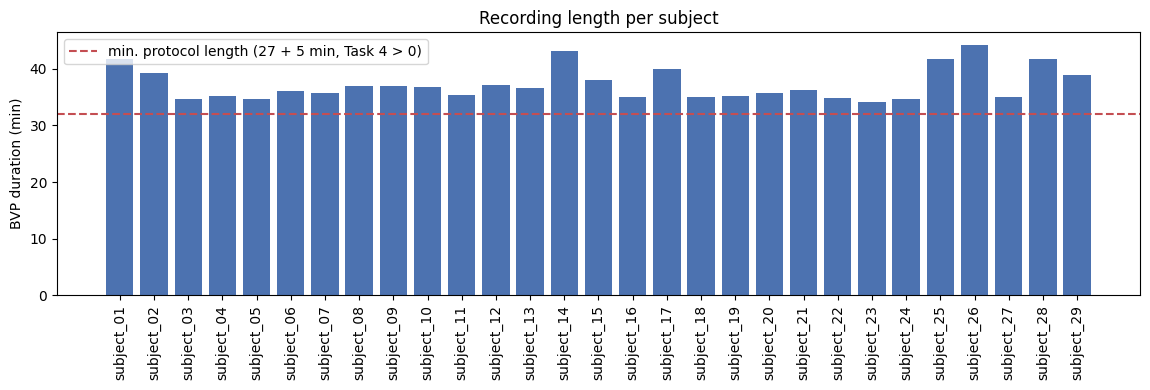

In [ ]:
def plot_durations(data):
    fig, ax = plt.subplots(figsize=(max(8, len(data) * 0.4), 4))
    ax.bar(data.index, data["dur_BVP_min"], color="#4c72b0")
    ax.axhline(32, color="#c44e52", ls="--", label="min. protocol length (27 + 5 min, Task 4 > 0)")
    ax.set_ylabel("BVP duration (min)")
    ax.set_title("Recording length per subject")
    ax.legend()
    plt.xticks(rotation=90)
    fig.tight_layout()
    return fig


plot_durations(visualization)
plt.show()

In [ ]:
def nominal_schedule(total_sec):
    """[(name, start_s, end_s, label)] or None if the recording is too short."""
    head_end = sum(d for _, d, _ in PROTOCOL_HEAD)
    tail_start = total_sec - sum(d for _, d, _ in PROTOCOL_TAIL)
    if tail_start <= head_end:
        return None
    segs, t = [], 0
    for name, d, lab in PROTOCOL_HEAD:
        segs.append((name, t, t + d, lab)); t += d
    segs.append(("Task 4", head_end, tail_start, 1)); t = tail_start
    for name, d, lab in PROTOCOL_TAIL:
        segs.append((name, t, t + d, lab)); t += d
    return segs


def count_expected_windows(dataset, win_sec=60):
    """Non-overlapping windows that fit inside each protocol segment (paper: 1068 over 29 subjects)."""
    total = 0
    for s in dataset.values():
        segs = nominal_schedule(session_duration(s))
        if segs is None:
            continue
        total += sum(int((b - a) // win_sec) for _, a, b, _ in segs)
    return total


print("non-overlapping 60 s windows under the nominal schedule:", count_expected_windows(dataset),
      "(paper: 1068 for 29 subjects)")

non-overlapping 60 s windows under the nominal schedule: 1069 (paper: 1068 for 29 subjects)


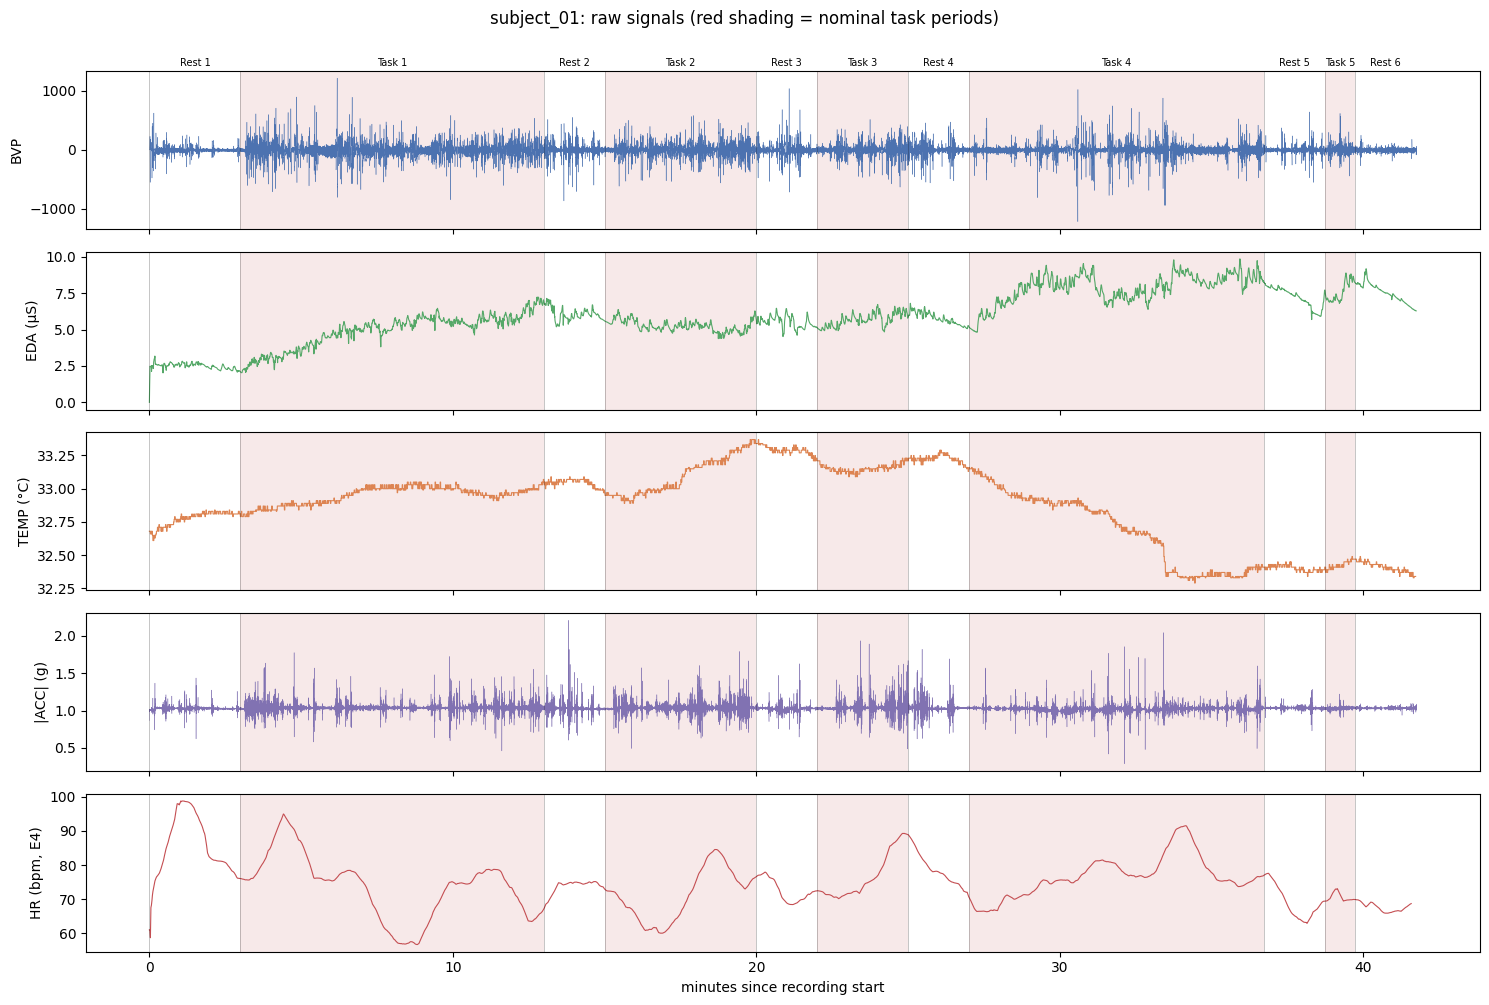

In [ ]:
def acc_magnitude_g(acc):
    """E4 ACC is in 1/64 g. Returns |a| in g."""
    return np.linalg.norm(acc, axis=1) / 64.0


def shade_protocol(ax, segs, label=False):
    if segs is None:
        return
    for name, a, b, lab in segs:
        if lab == 1:
            ax.axvspan(a / 60, b / 60, color="#c44e52", alpha=0.12, lw=0)
        ax.axvline(a / 60, color="k", lw=0.4, alpha=0.4)
        if label:
            ax.text((a + b) / 120, 1.02, name, transform=ax.get_xaxis_transform(),
                    ha="center", va="bottom", fontsize=7)


def plot_session_overview(subj, schedule=True):
    """All modalities for one subject, nominal protocol shaded (red = task). x axis in minutes."""
    segs = nominal_schedule(session_duration(subj)) if schedule else None
    sig = subj["signals"]
    fig, axes = plt.subplots(5, 1, figsize=(15, 10), sharex=True)

    axes[0].plot(time_axis(subj, "BVP") / 60, sig["BVP"]["data"], lw=0.3, color="#4c72b0")
    axes[0].set_ylabel("BVP")
    axes[1].plot(time_axis(subj, "EDA") / 60, sig["EDA"]["data"], lw=0.8, color="#55a868")
    axes[1].set_ylabel("EDA (µS)")
    axes[2].plot(time_axis(subj, "TEMP") / 60, sig["TEMP"]["data"], lw=0.8, color="#dd8452")
    axes[2].set_ylabel("TEMP (°C)")
    axes[3].plot(time_axis(subj, "ACC") / 60, acc_magnitude_g(sig["ACC"]["data"]), lw=0.3, color="#8172b2")
    axes[3].set_ylabel("|ACC| (g)")
    if "HR" in sig:
        axes[4].plot(time_axis(subj, "HR") / 60, sig["HR"]["data"], lw=0.8, color="#c44e52")
    axes[4].set_ylabel("HR (bpm, E4)")
    axes[4].set_xlabel("minutes since recording start")

    for i, ax in enumerate(axes):
        shade_protocol(ax, segs, label=(i == 0))
    if subj["tags"] is not None:
        for t in subj["tags"] - subj["t0"]:
            for ax in axes:
                ax.axvline(t / 60, color="orange", lw=1.2)
    fig.suptitle(f"{subj['subject']}: raw signals (red shading = nominal task periods)", y=1.0)
    fig.tight_layout()
    return fig


sid0 = list(dataset)[0]
plot_session_overview(dataset[sid0])
plt.show()

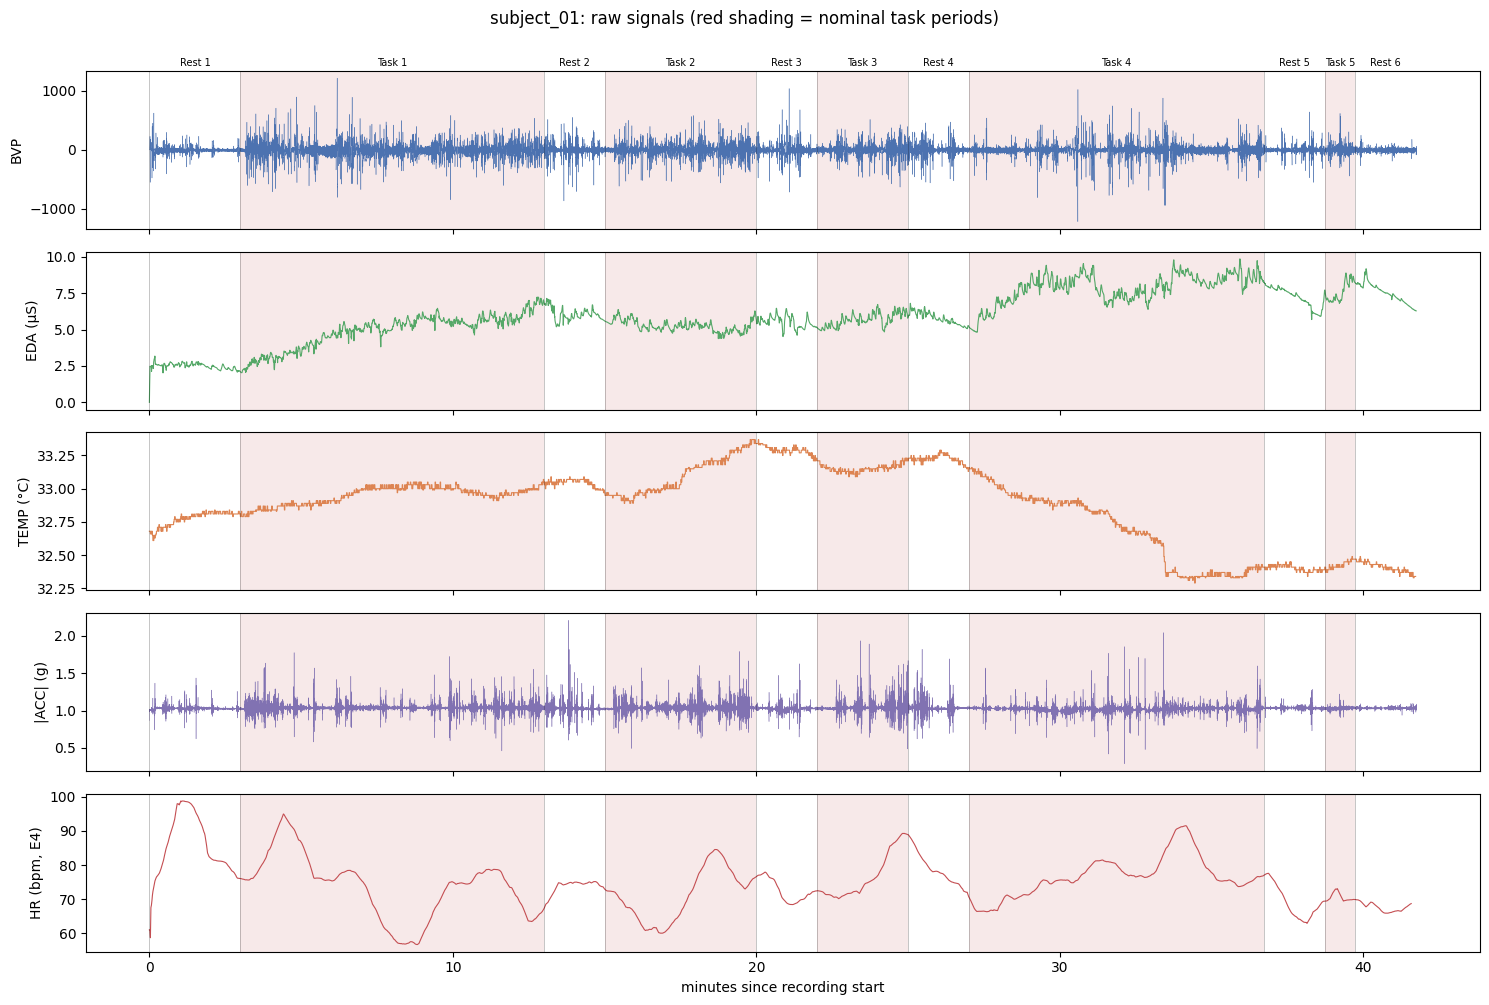

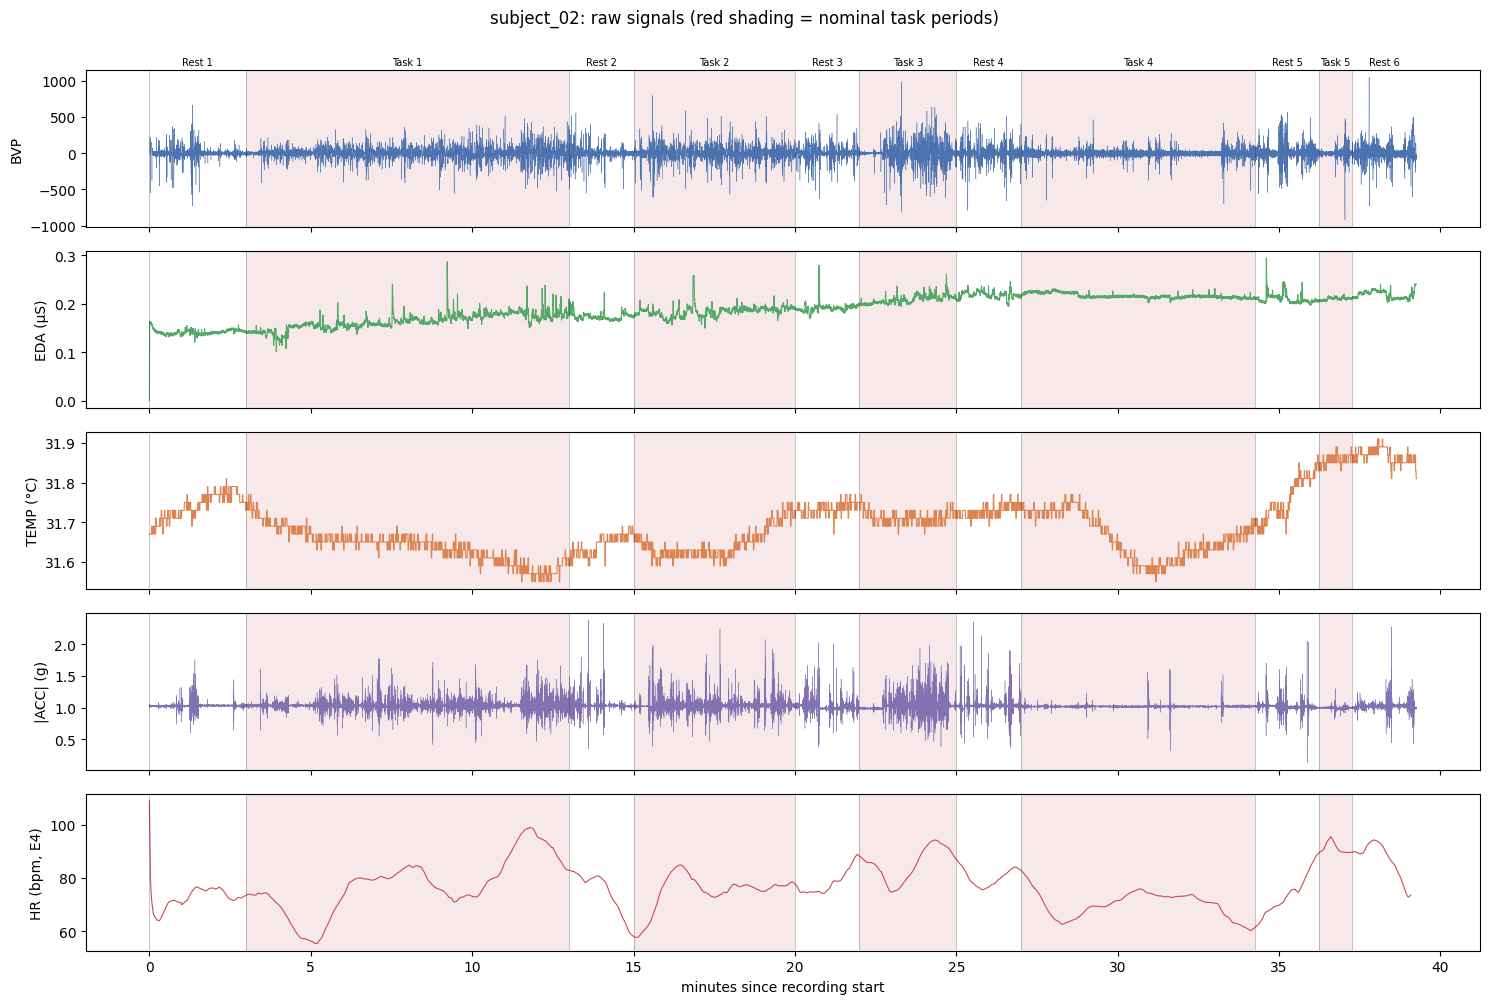

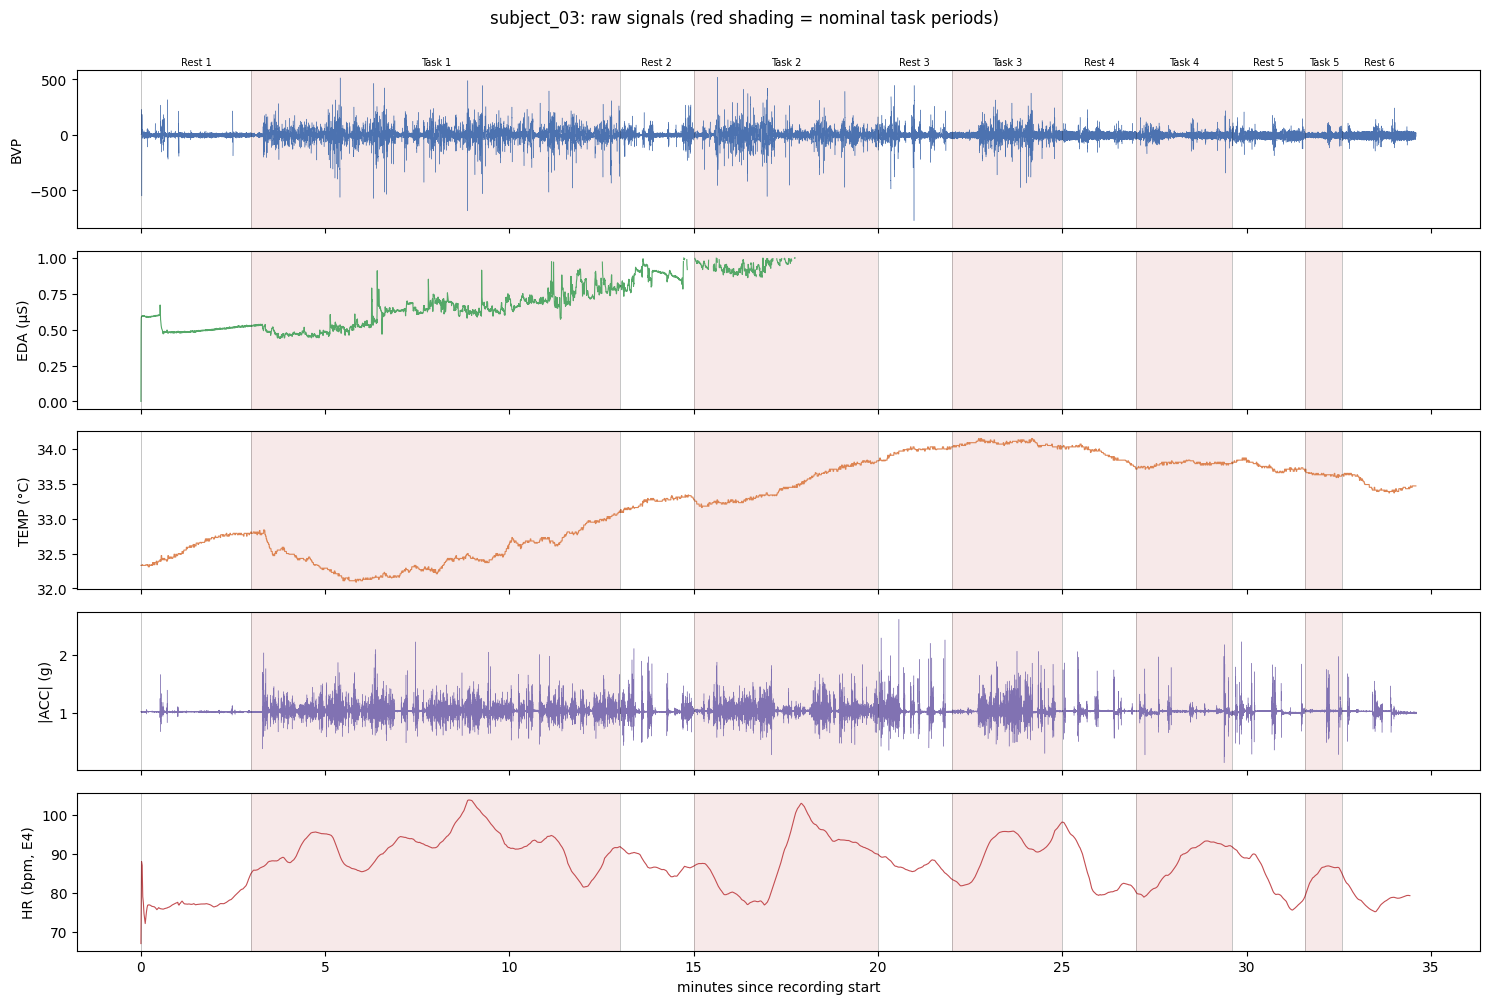

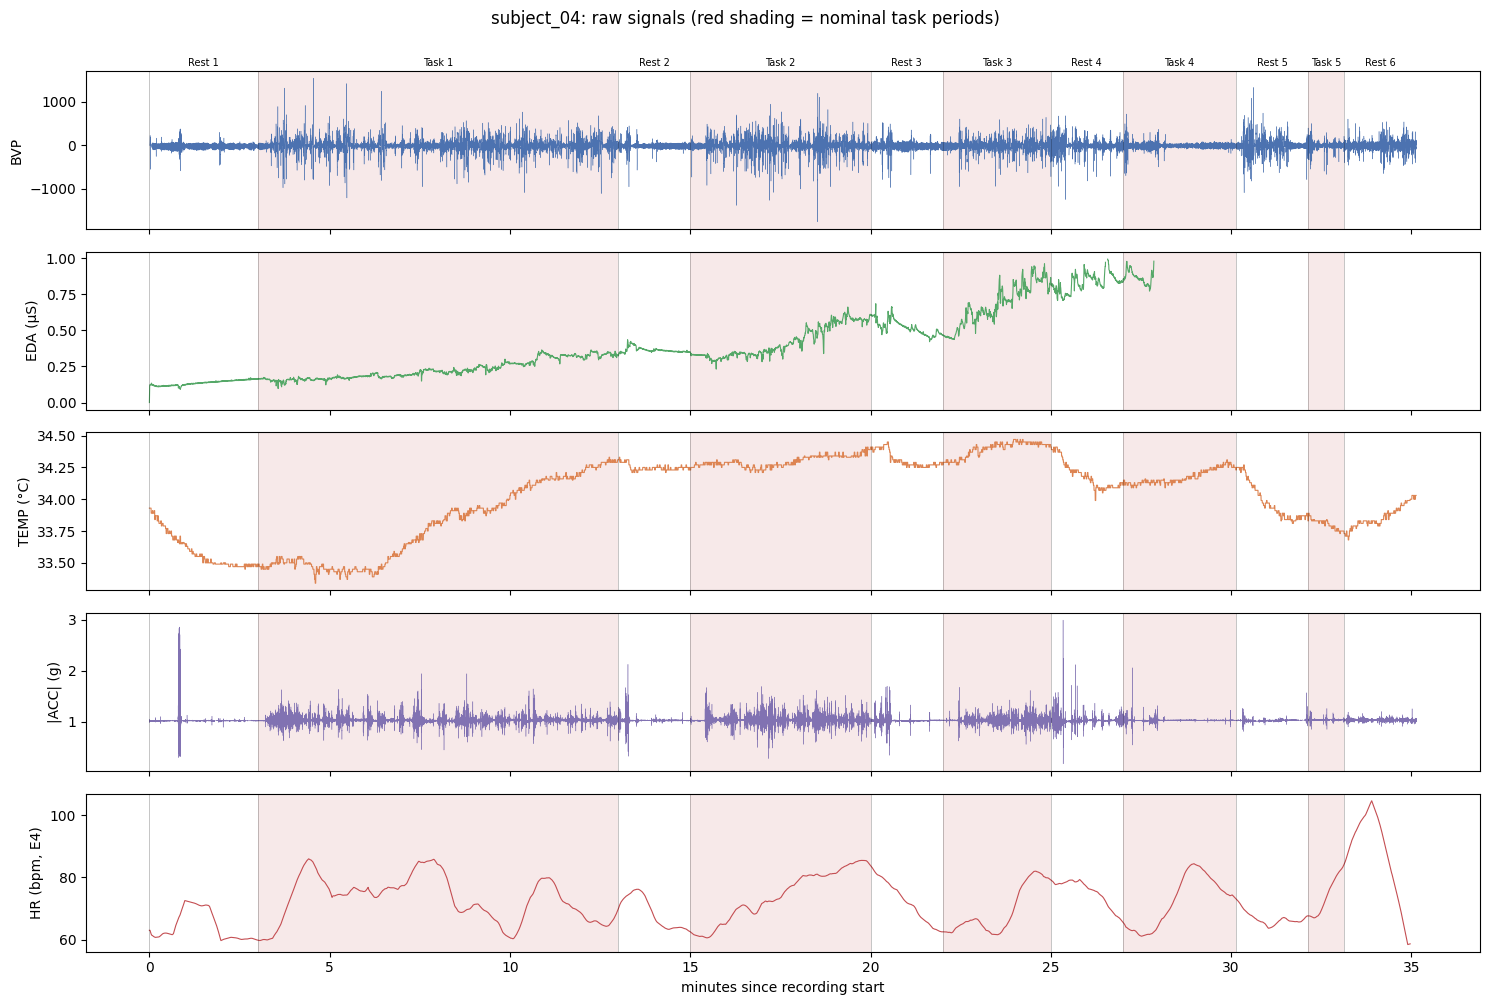

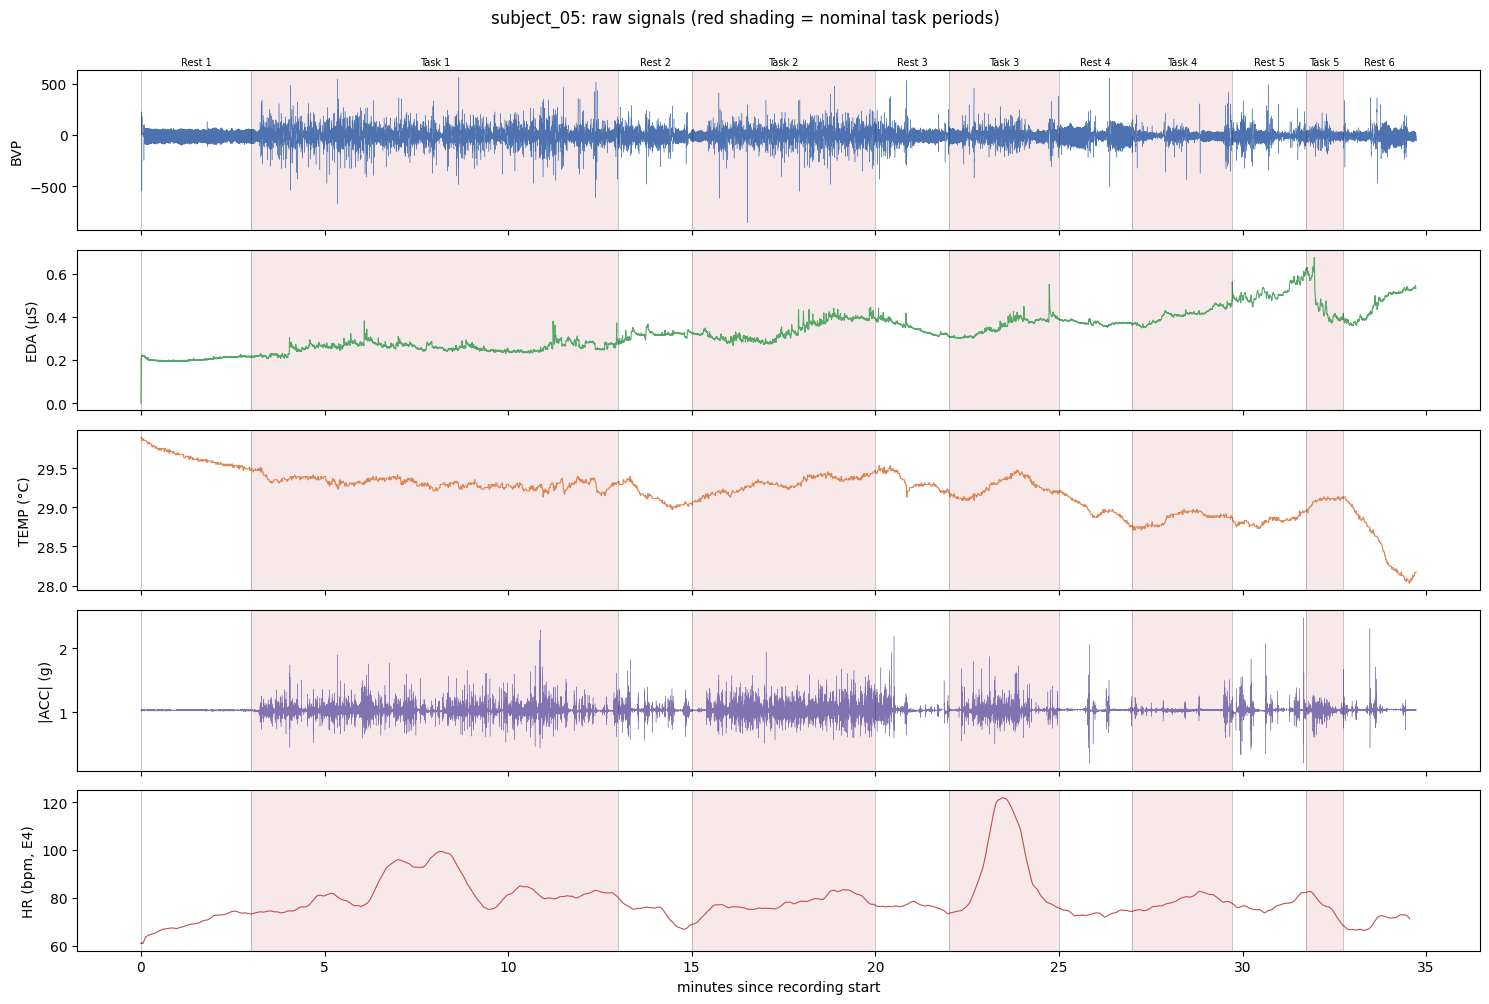

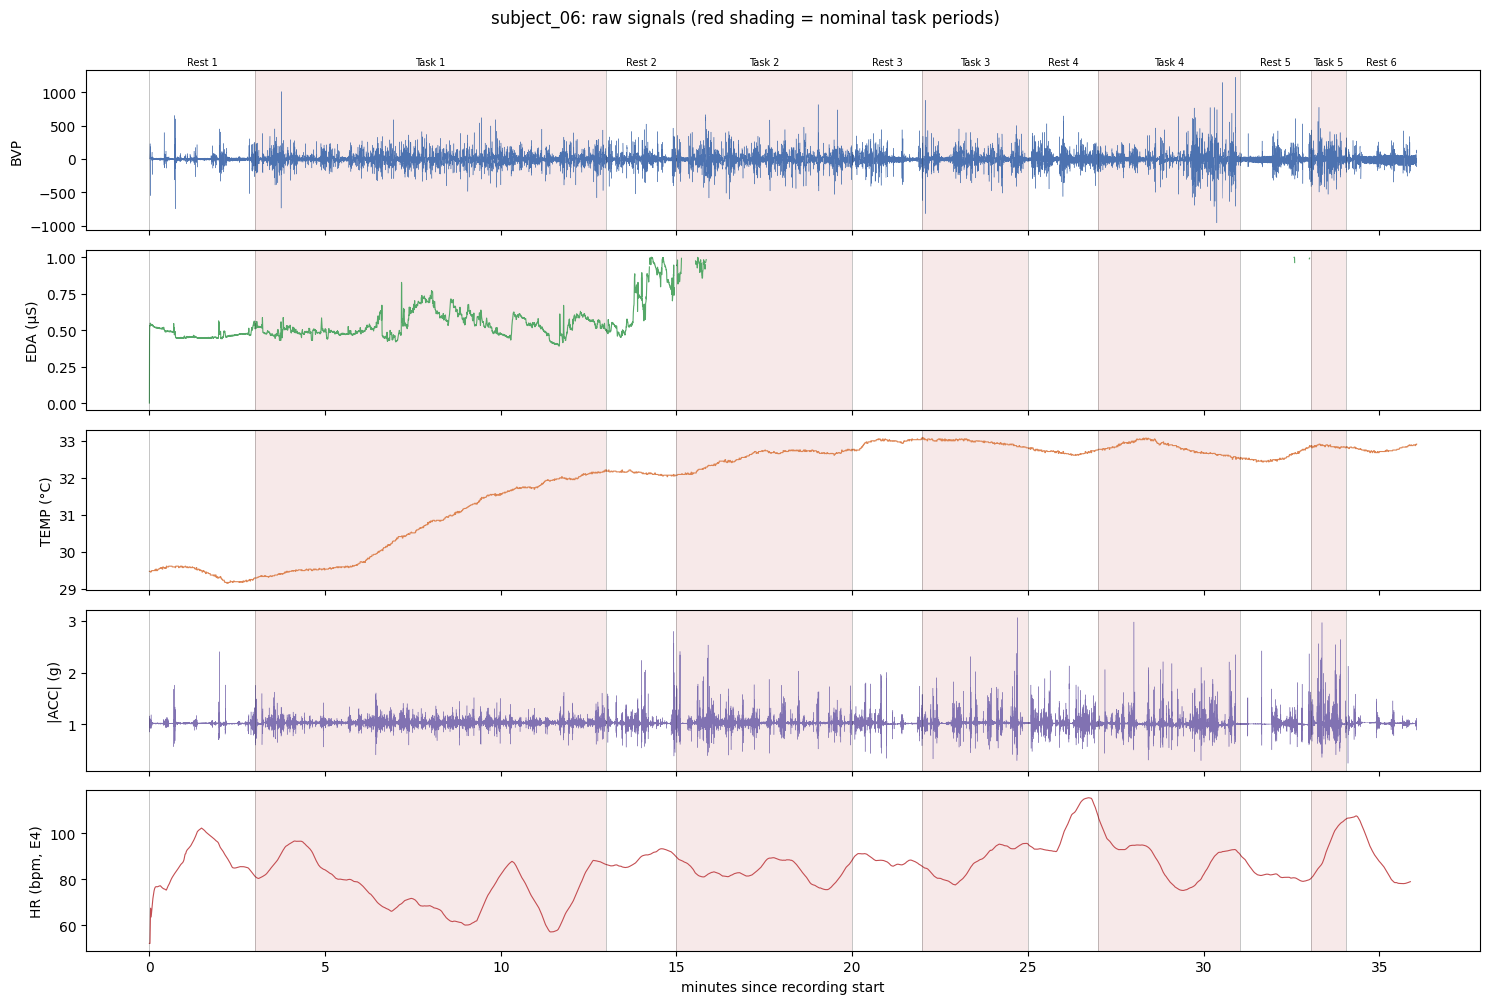

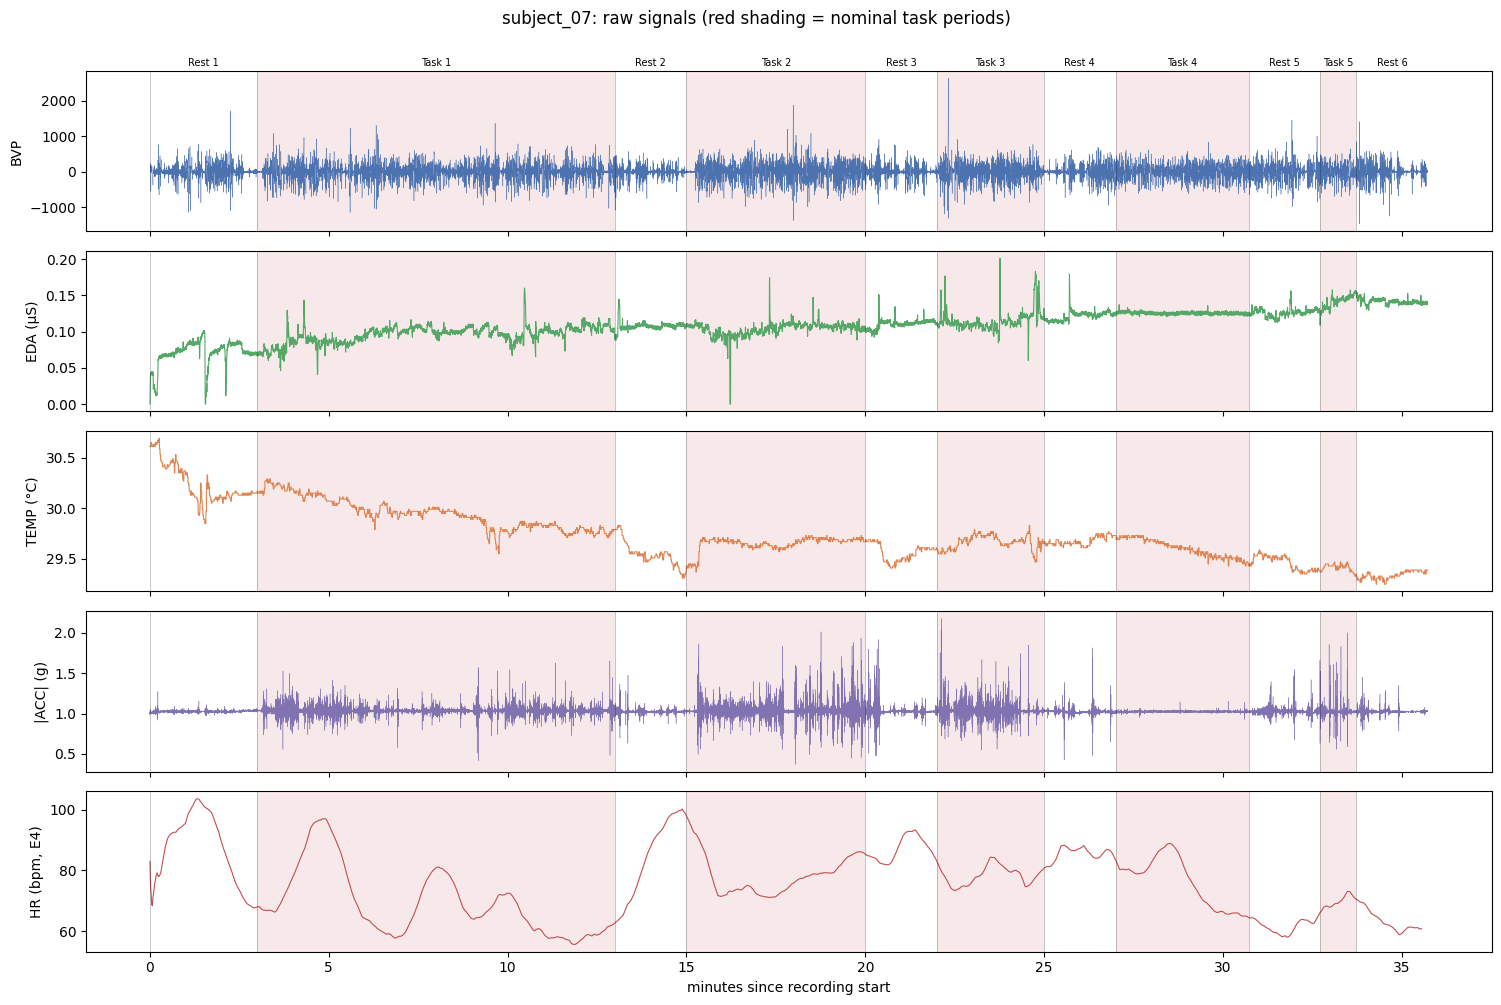

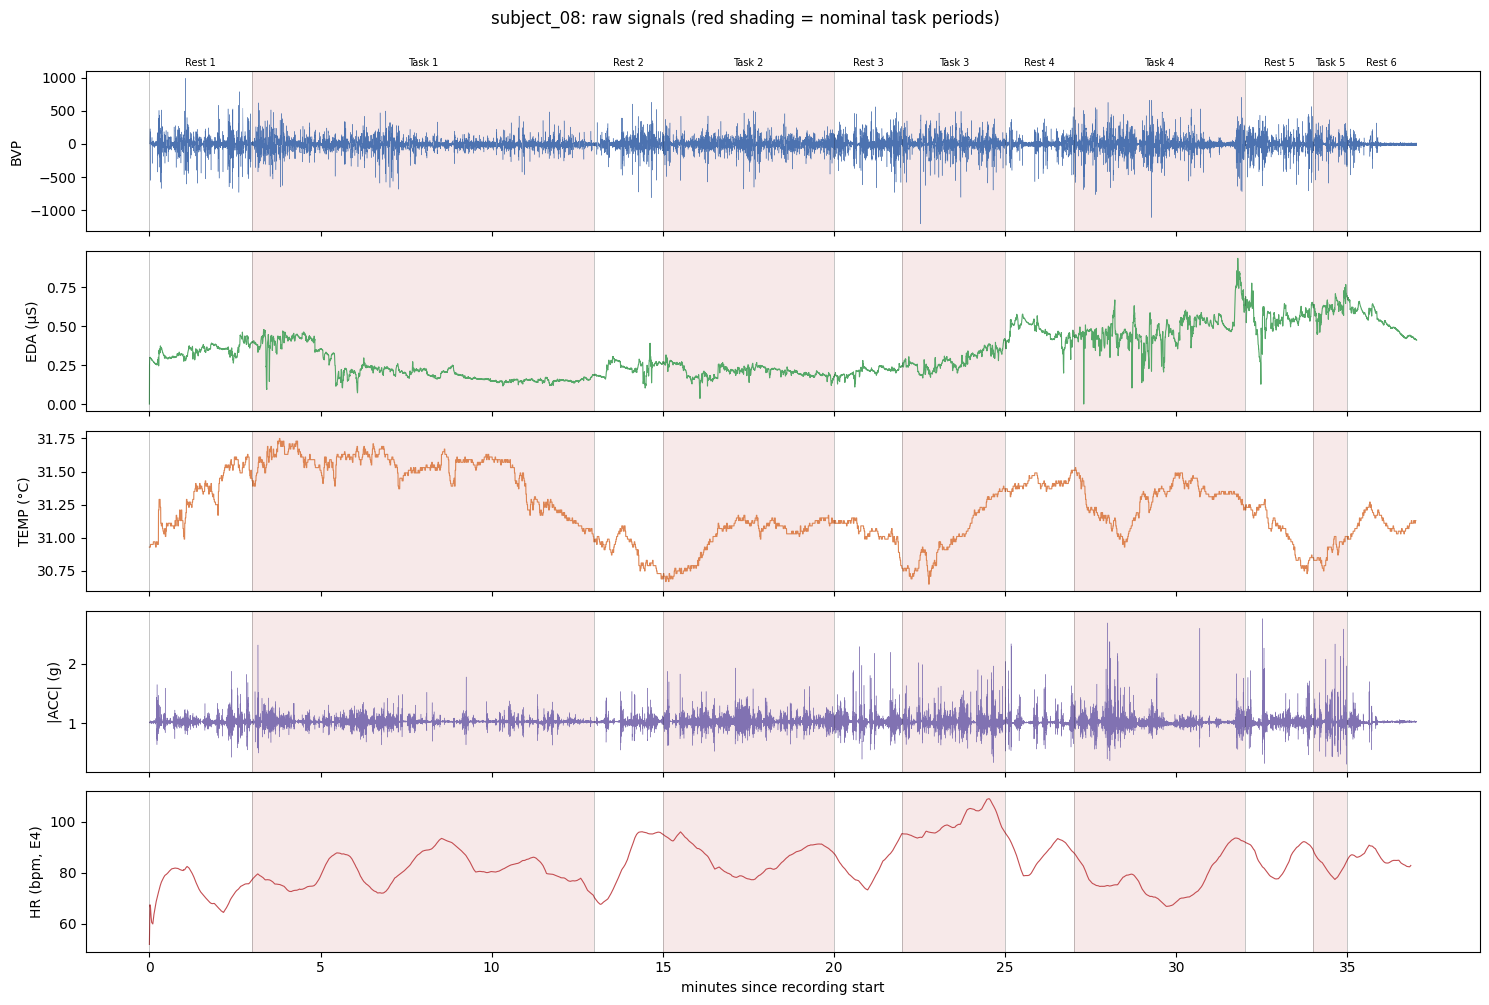

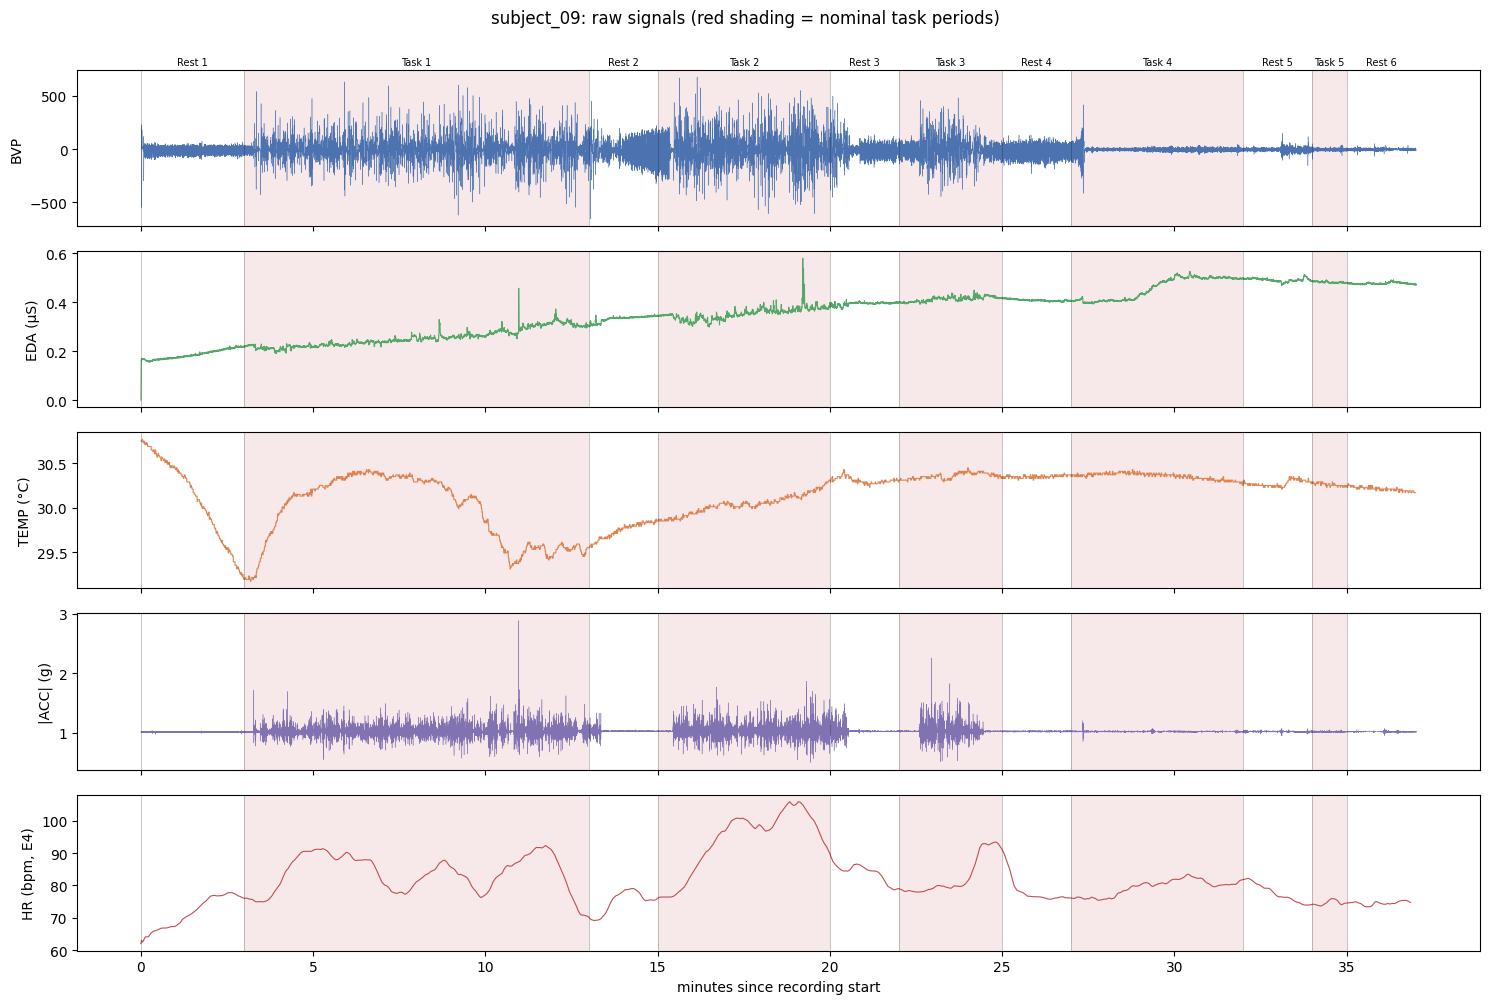

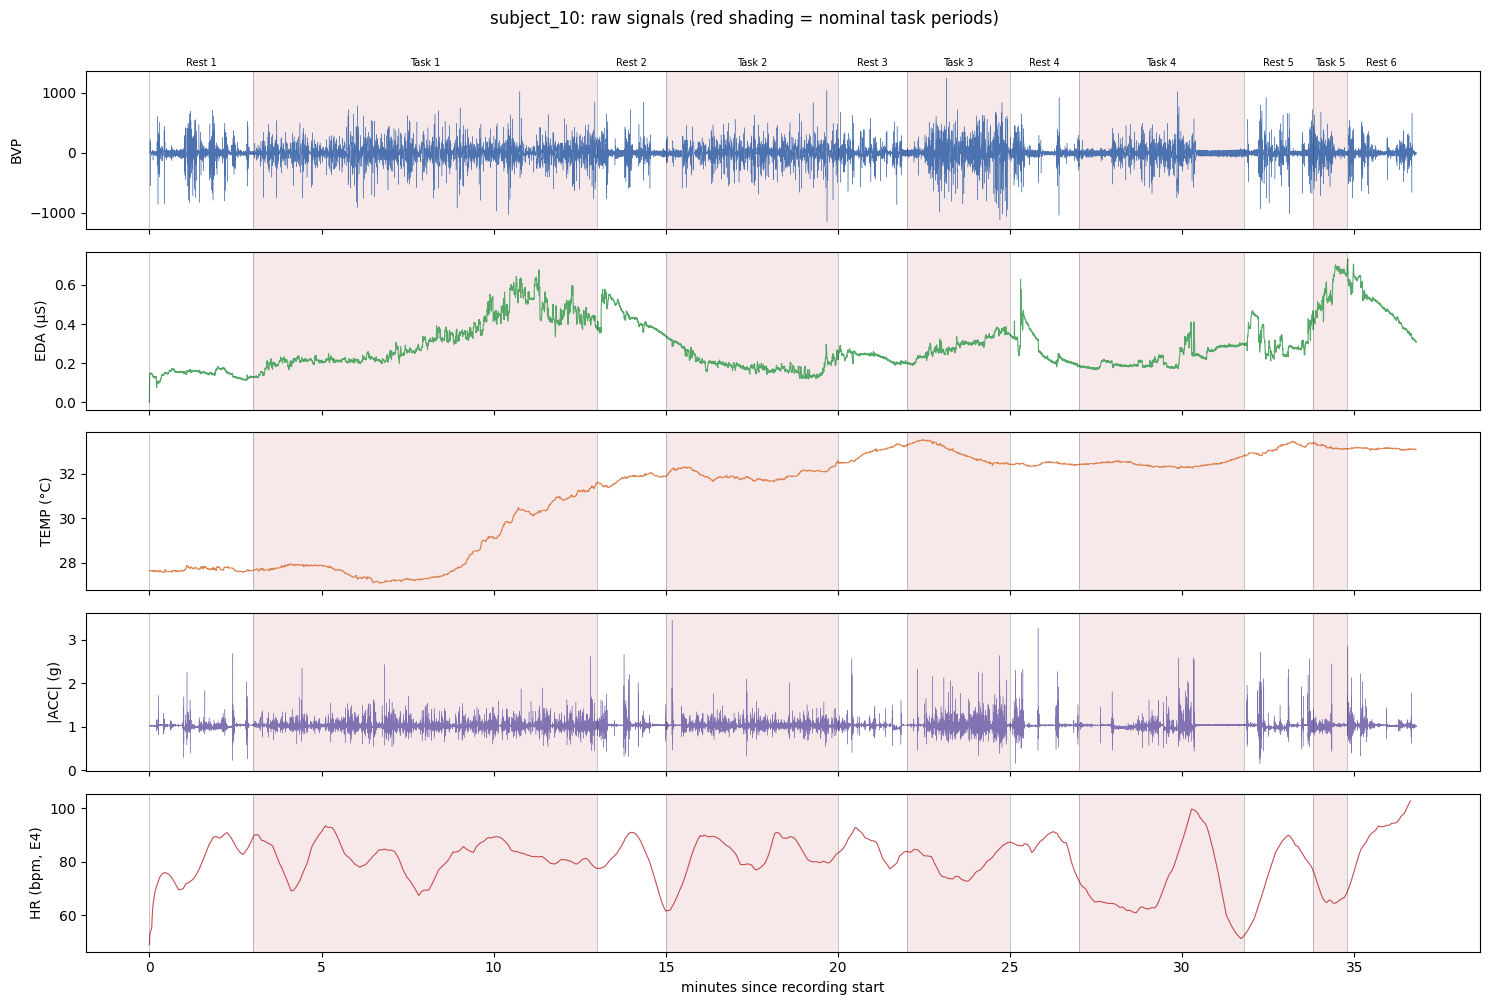

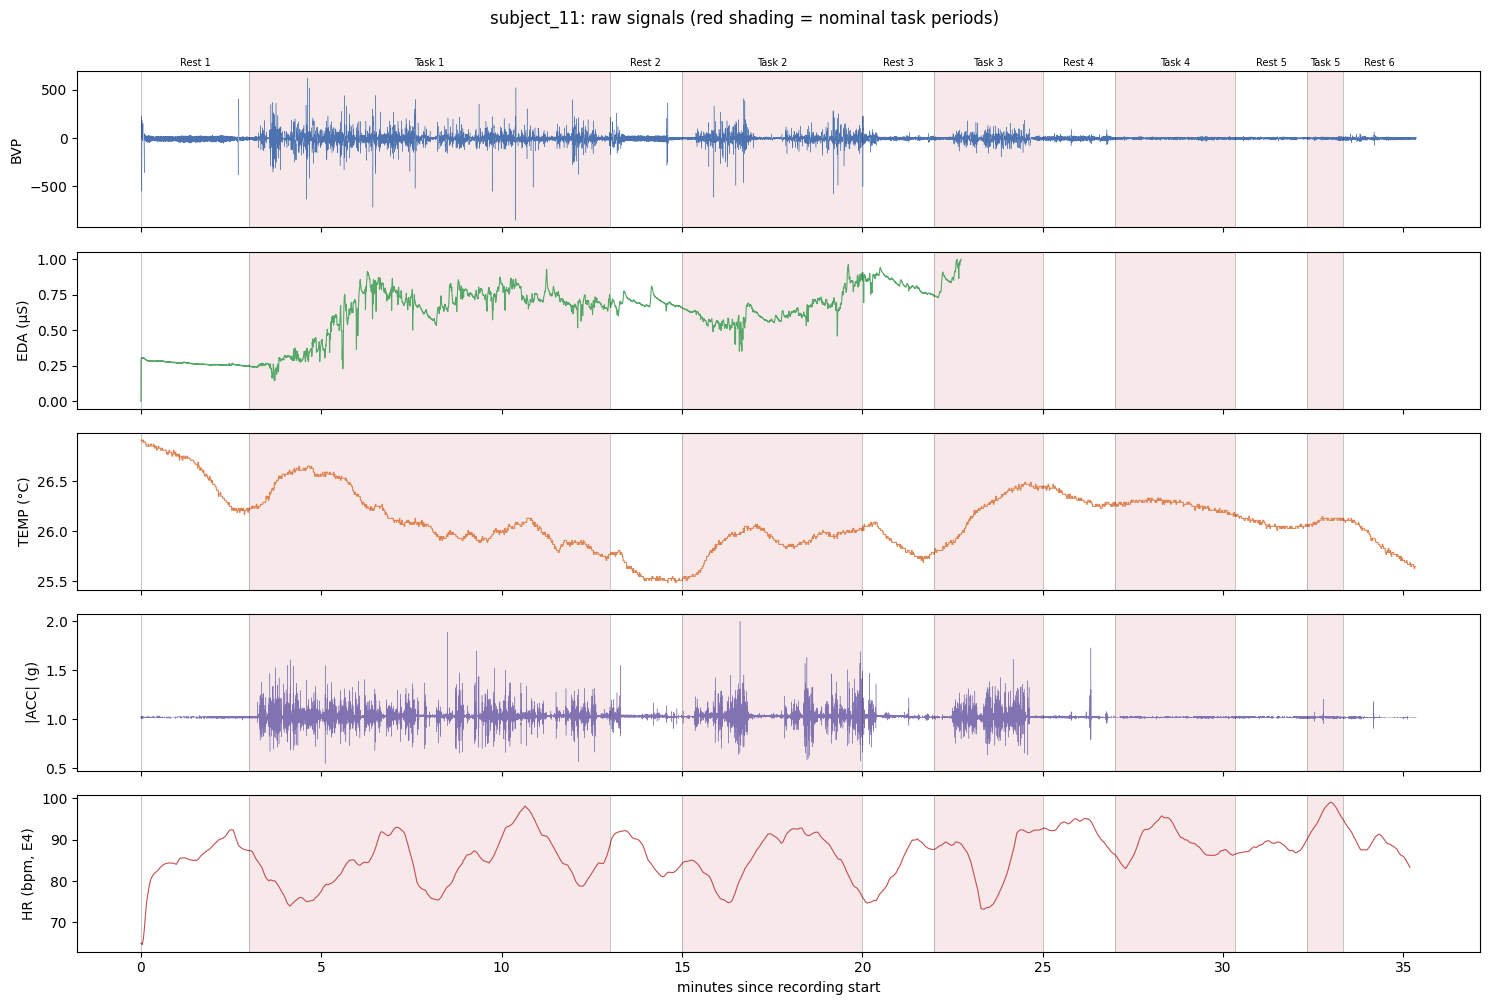

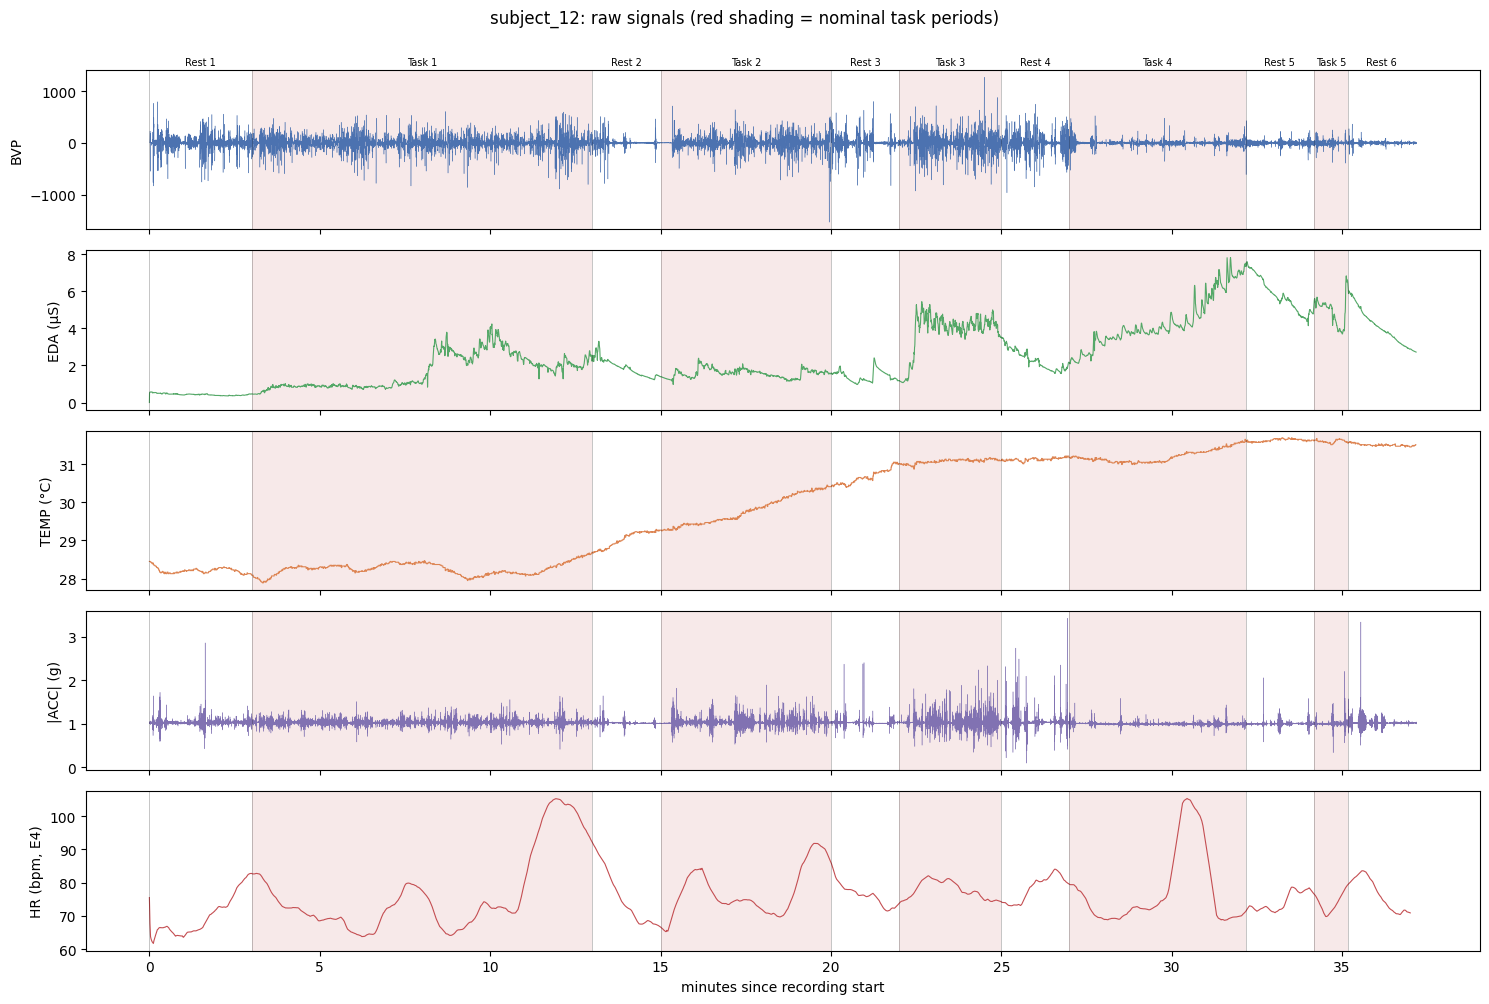

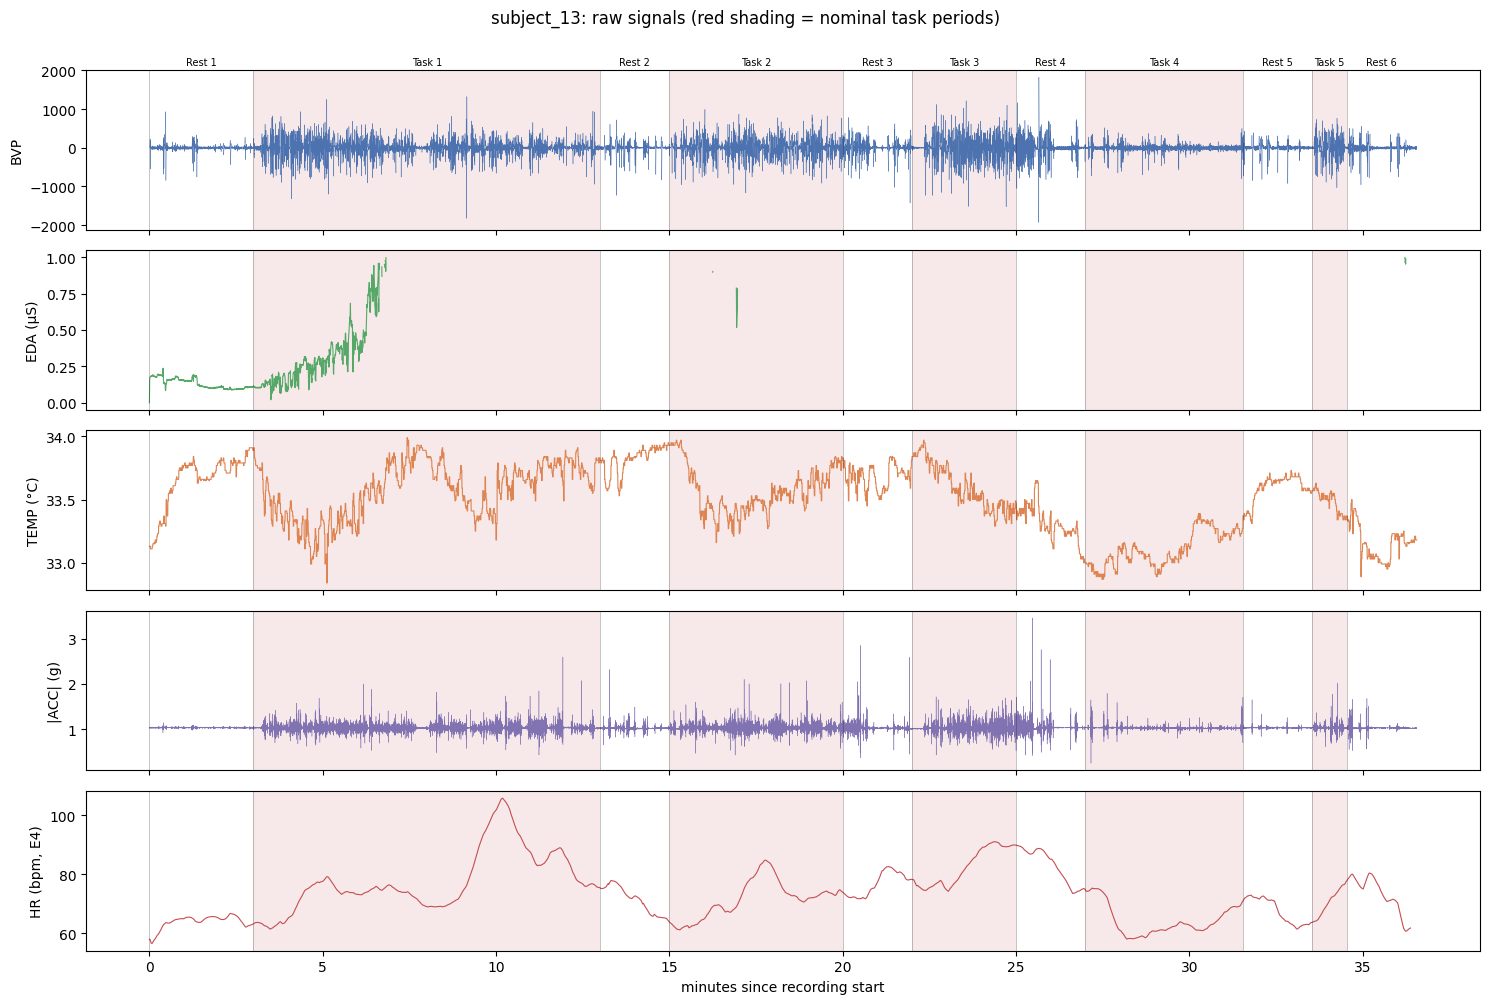

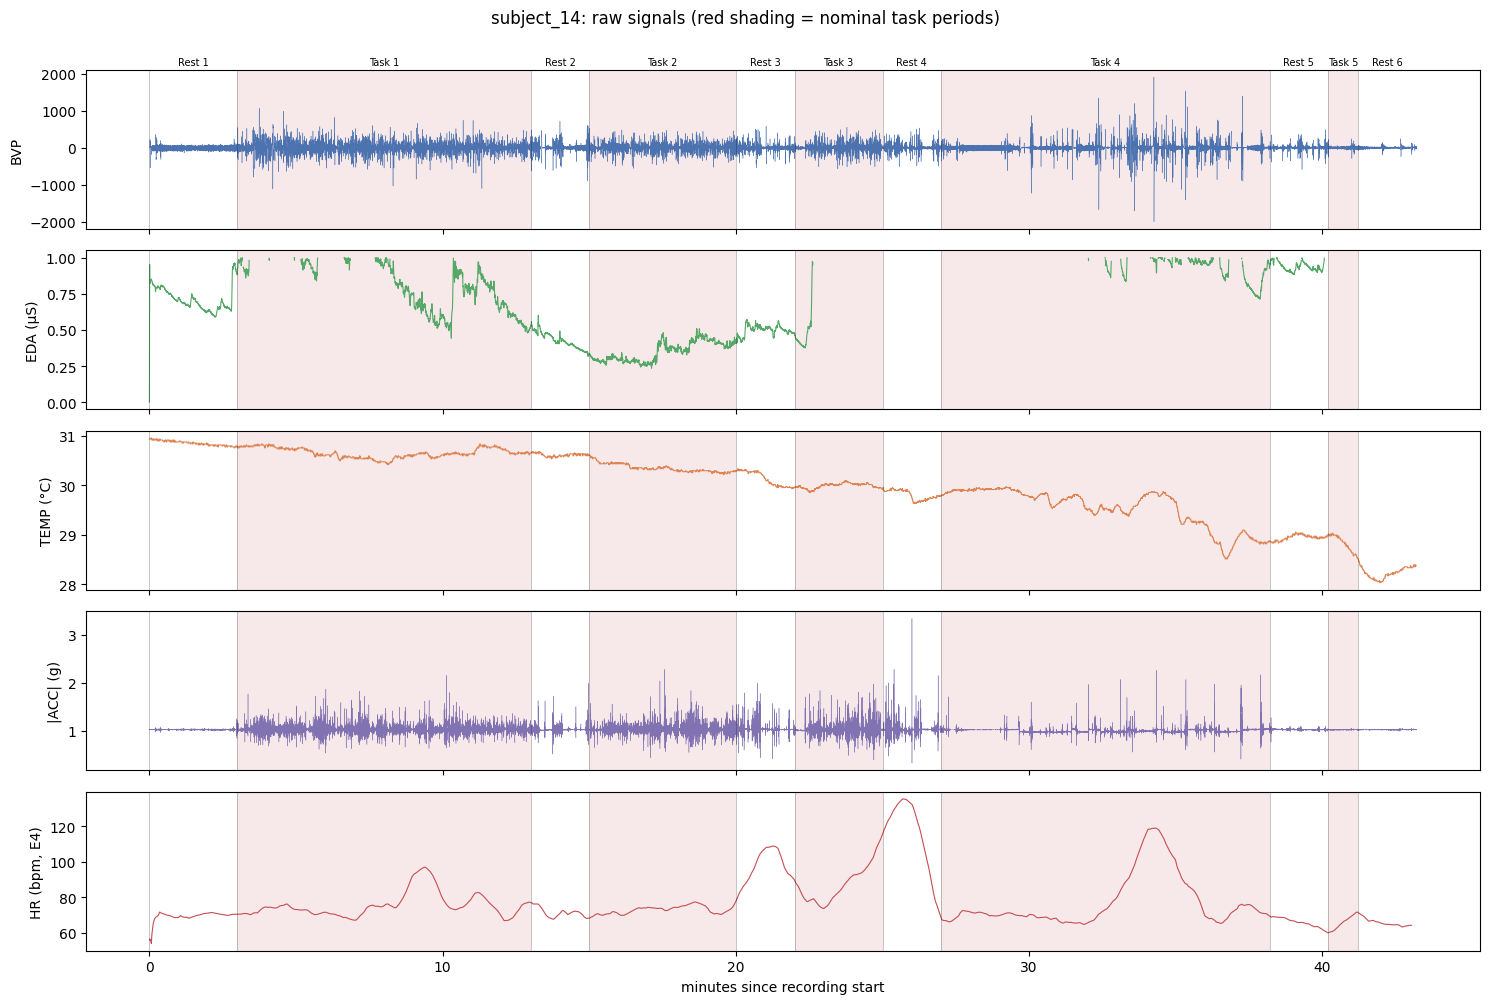

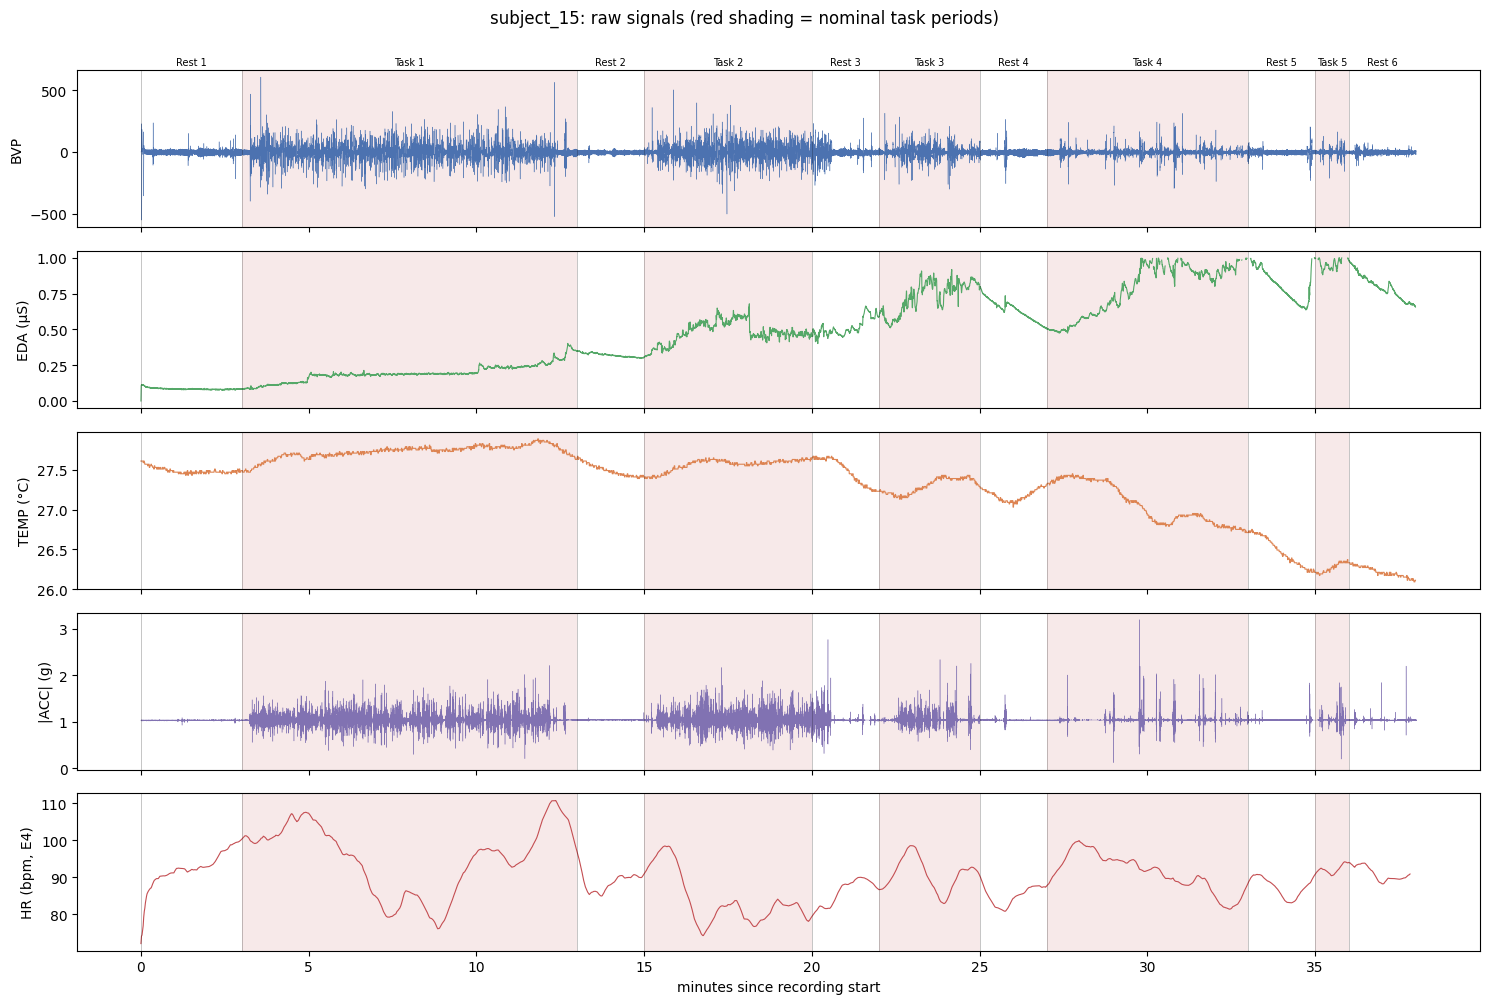

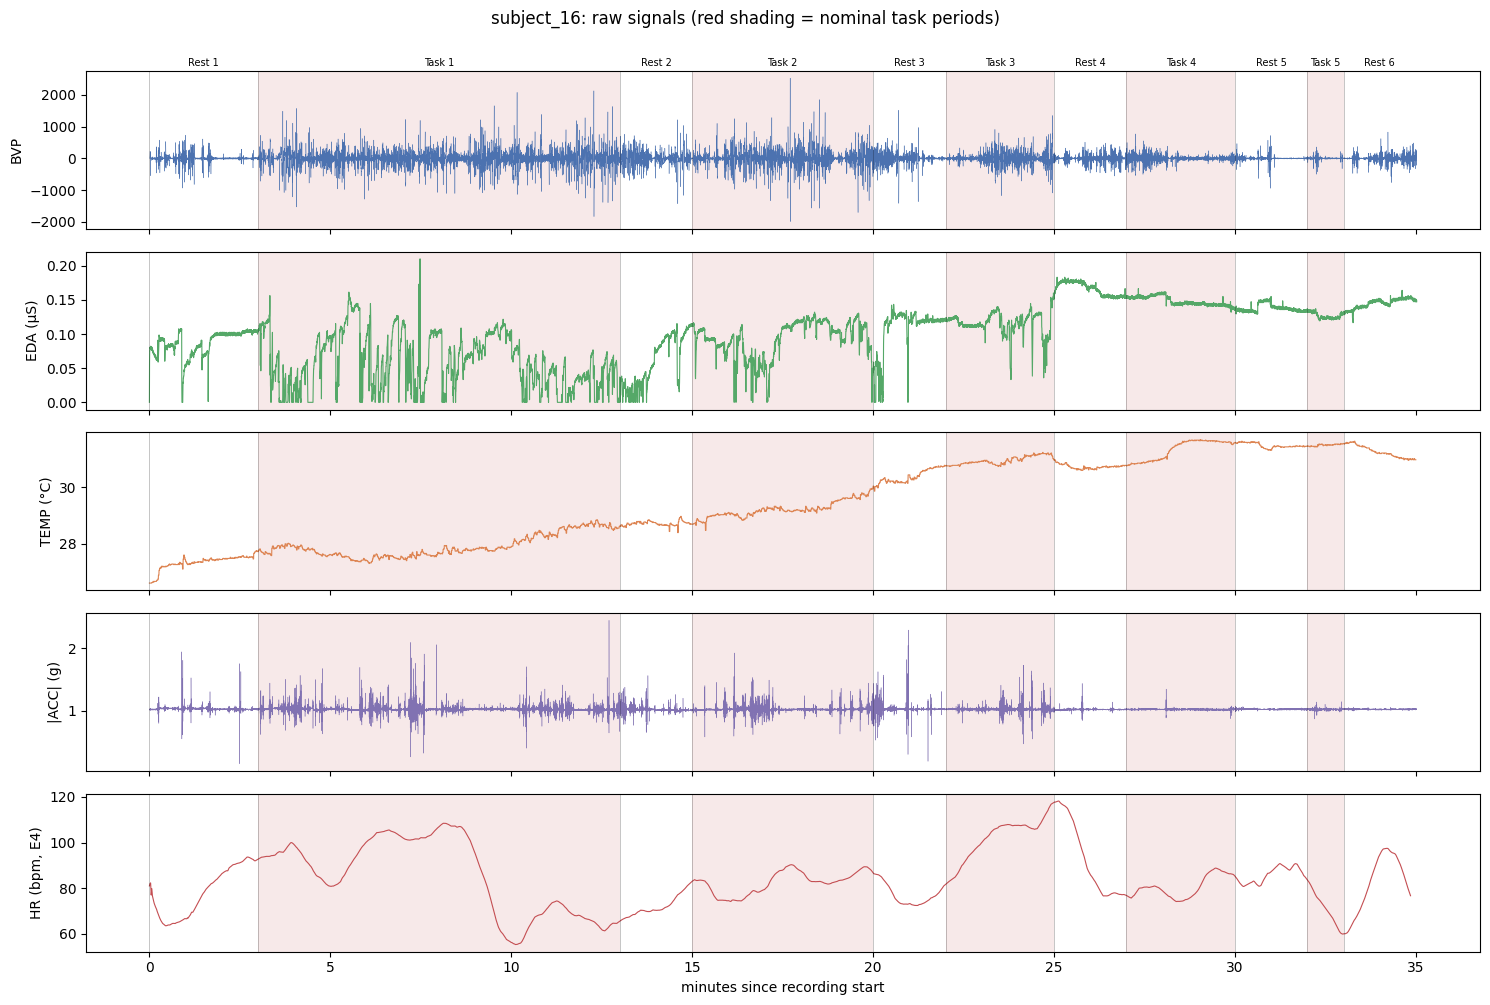

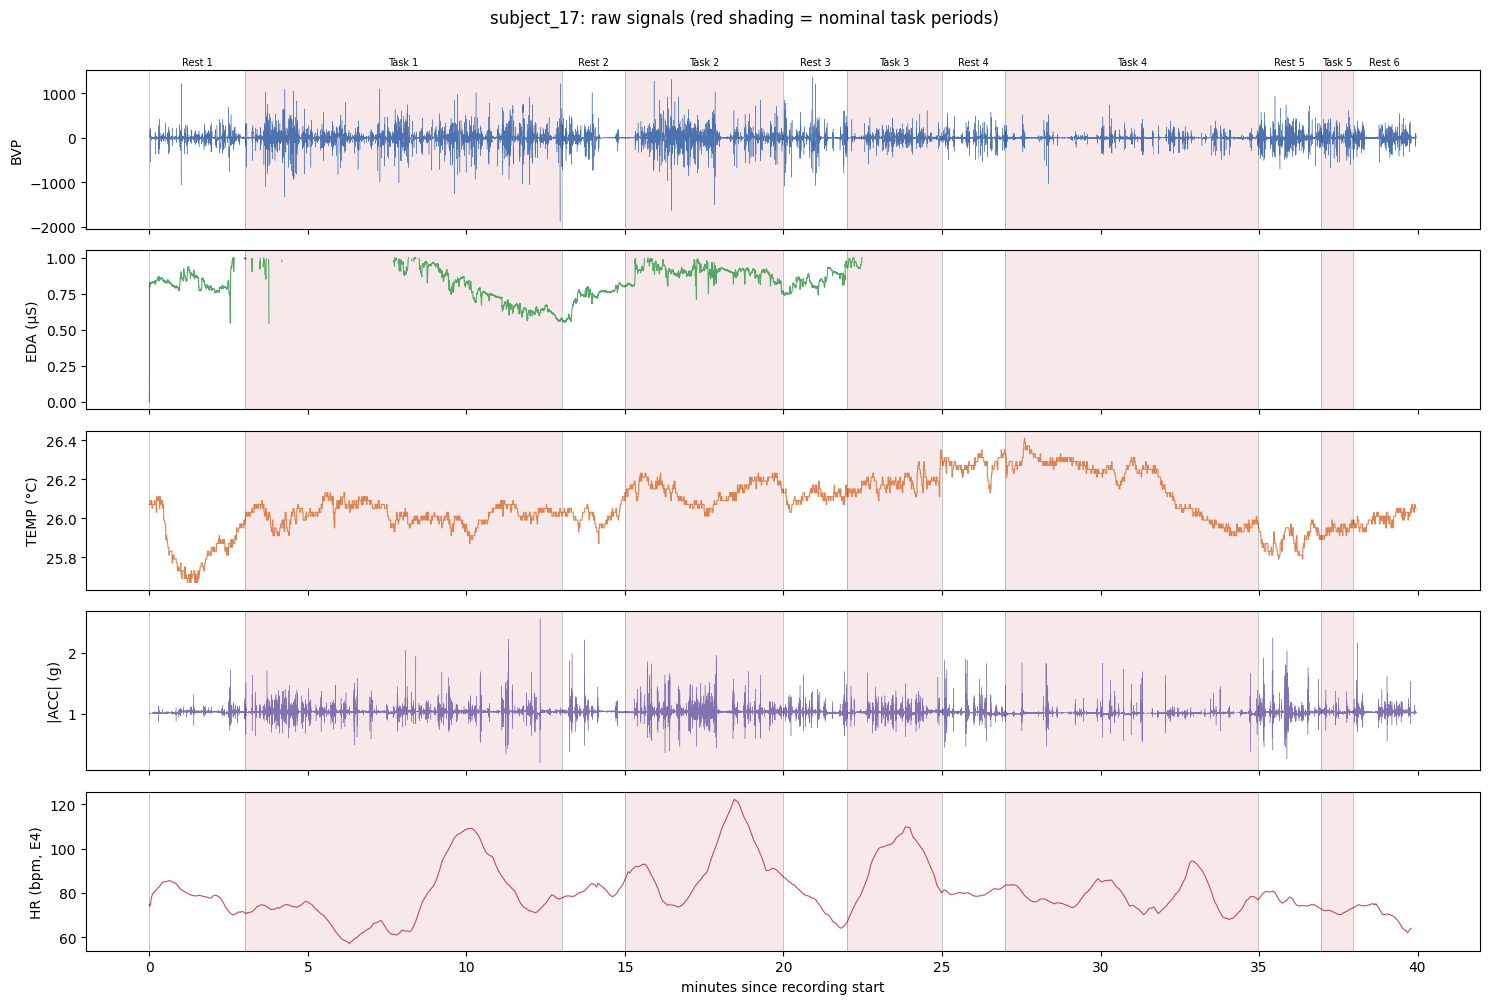

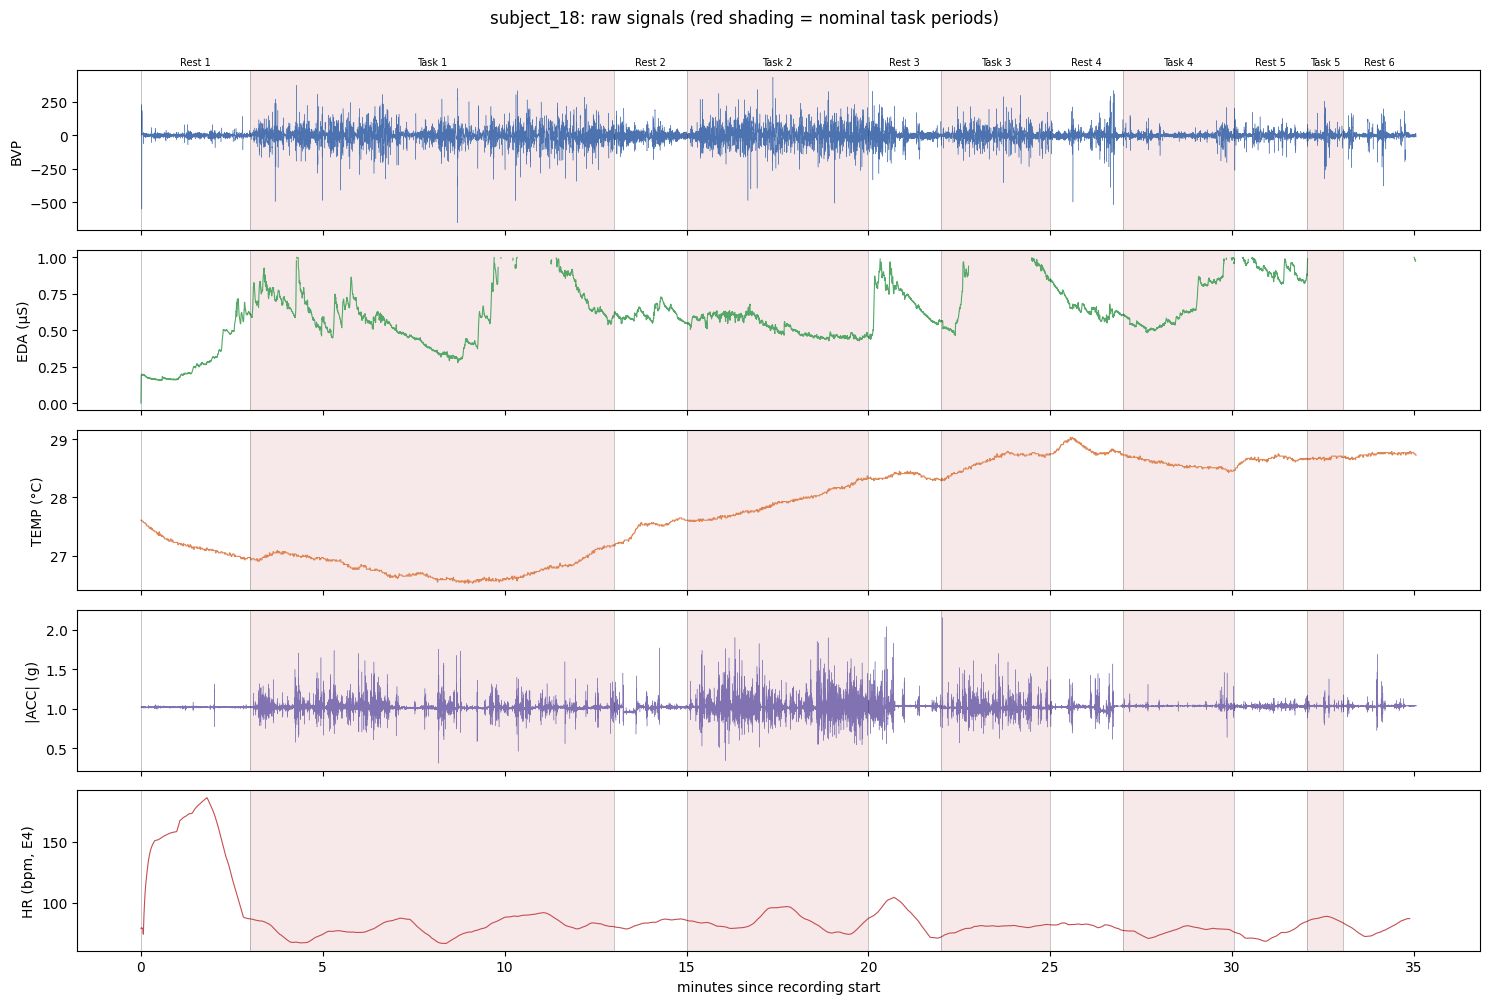

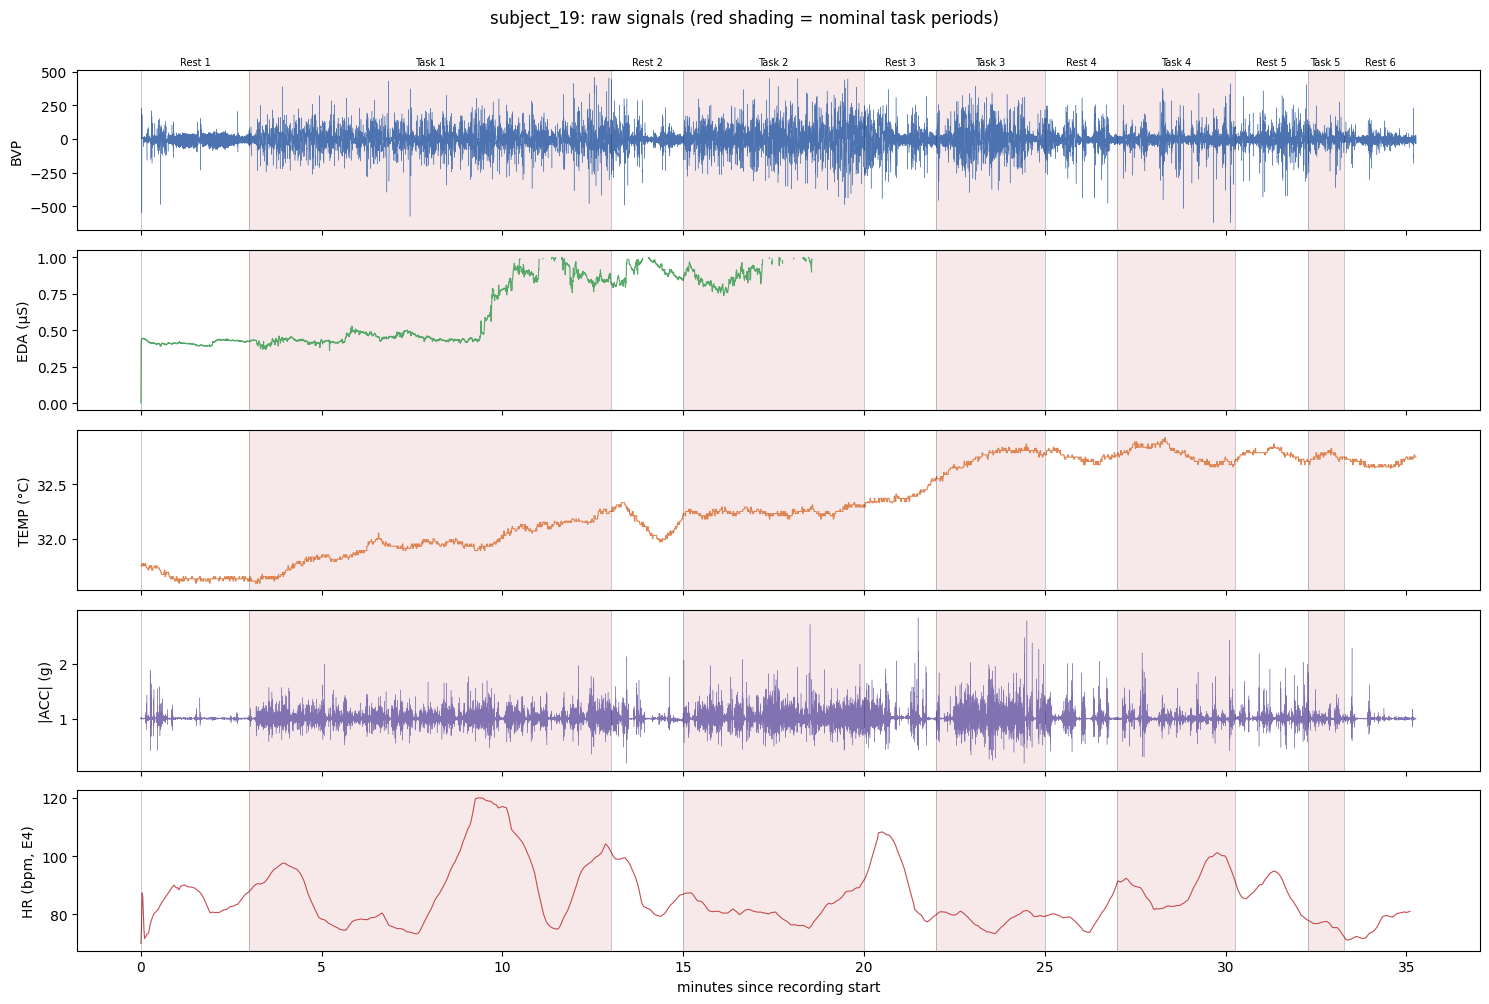

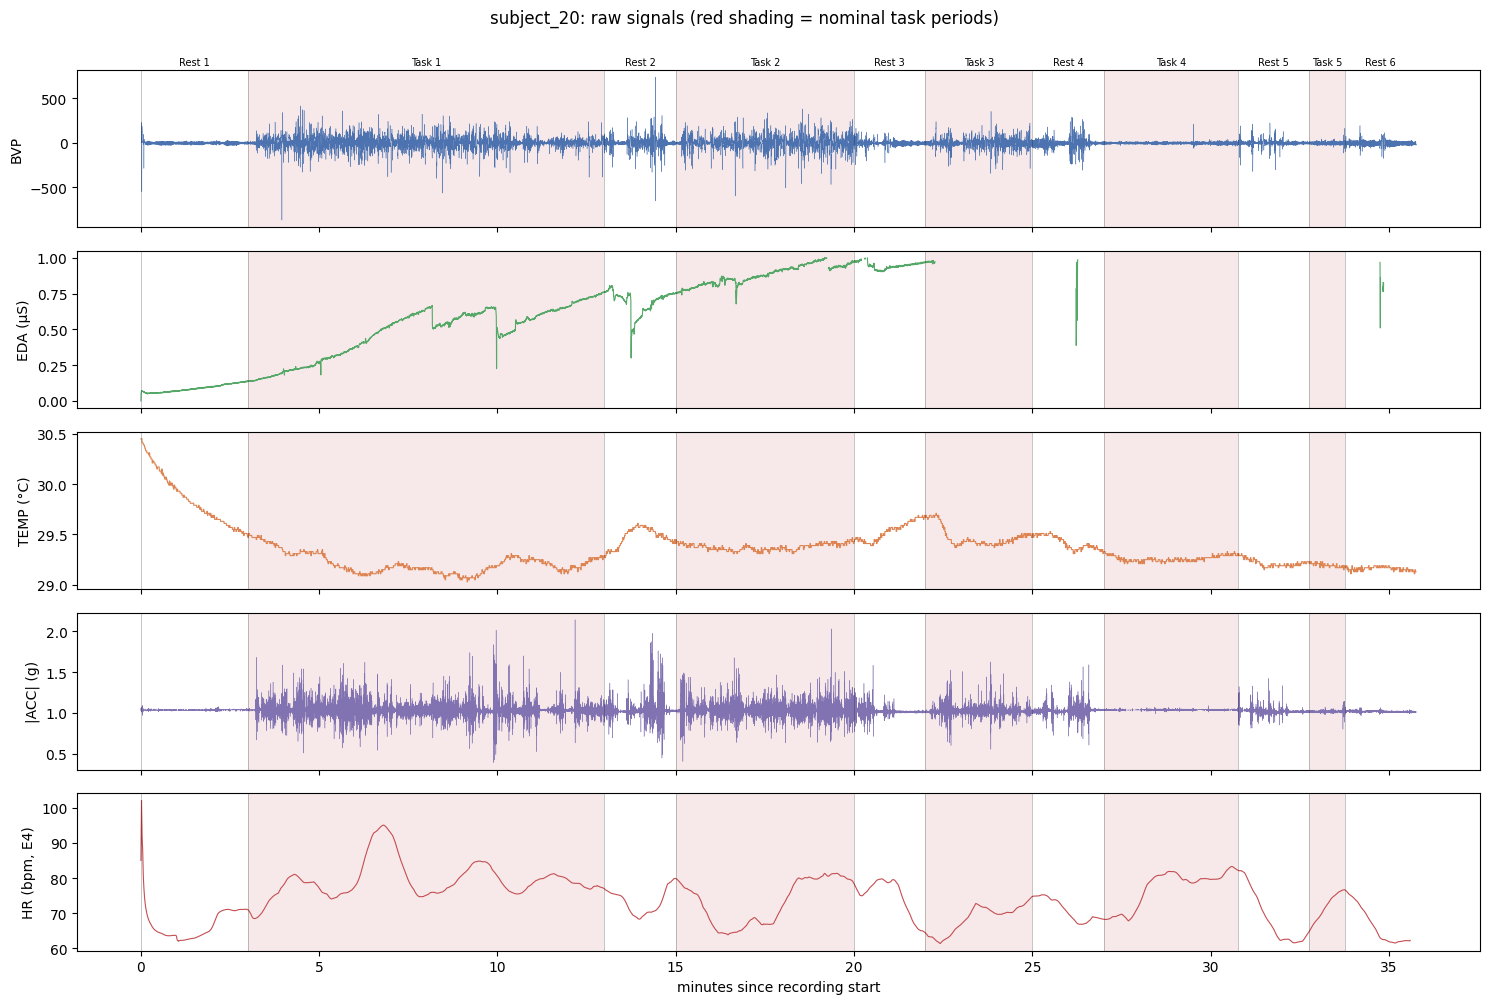

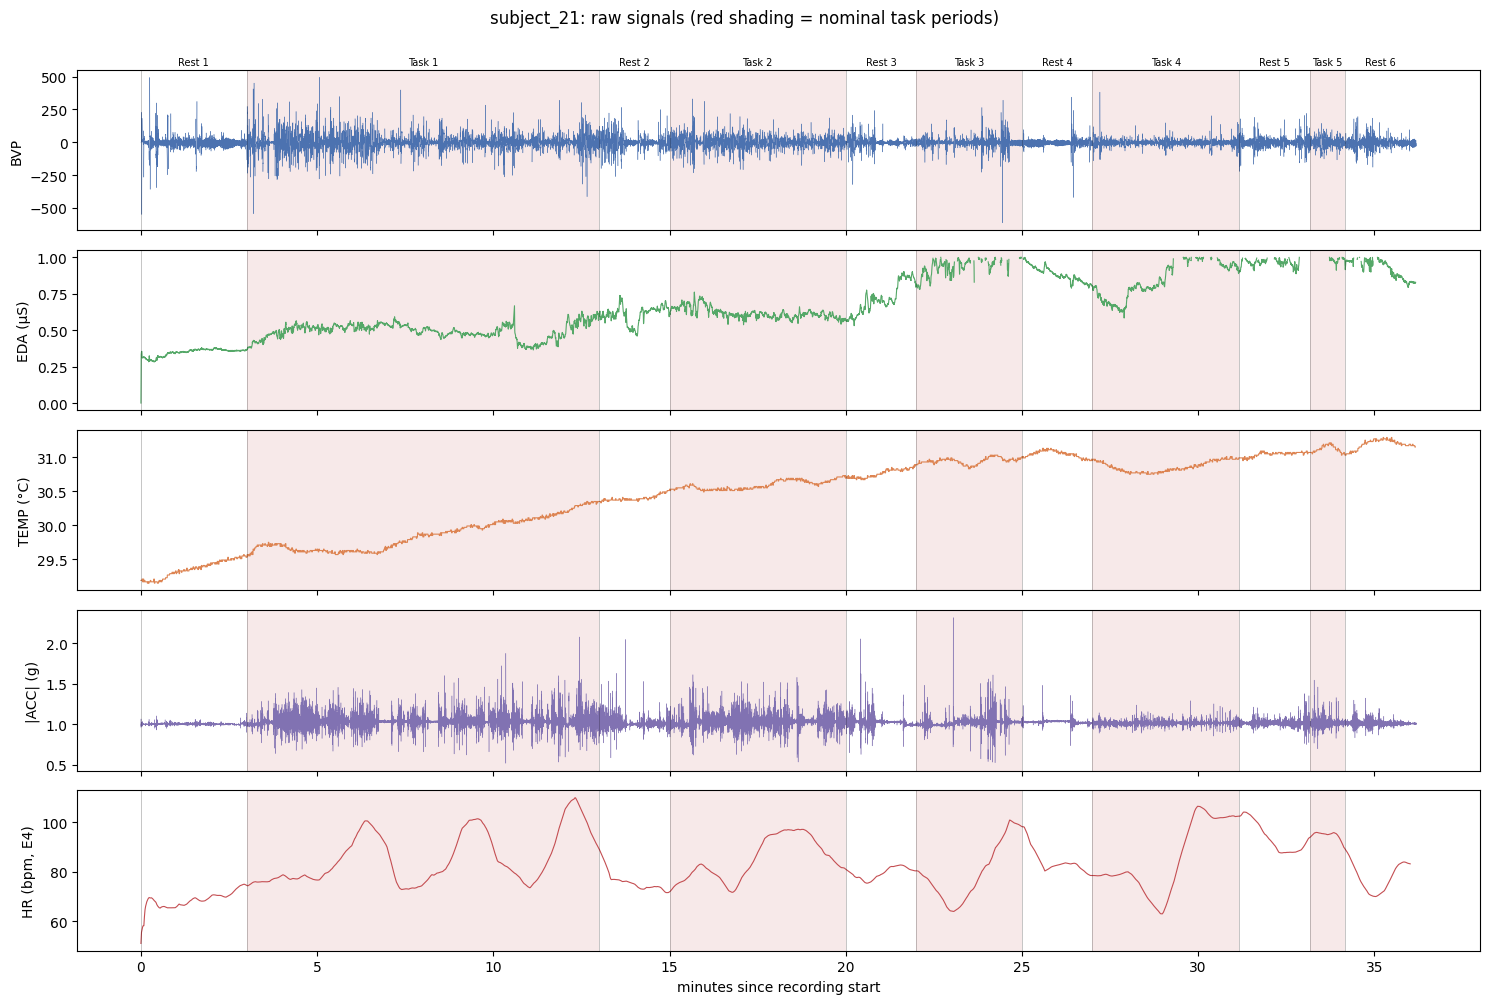

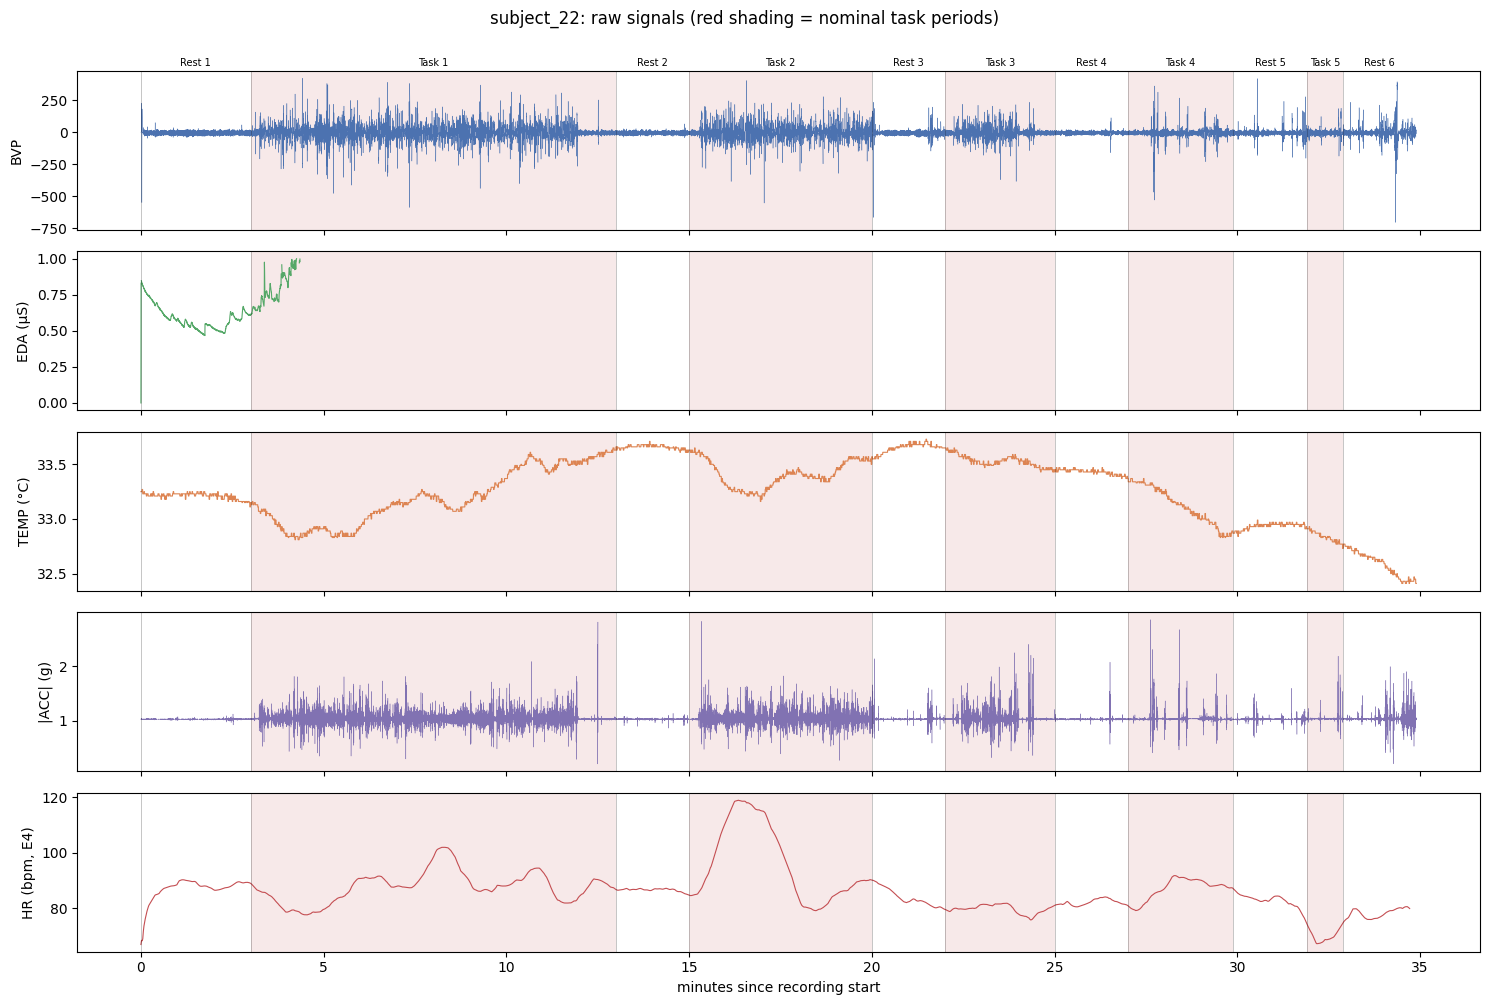

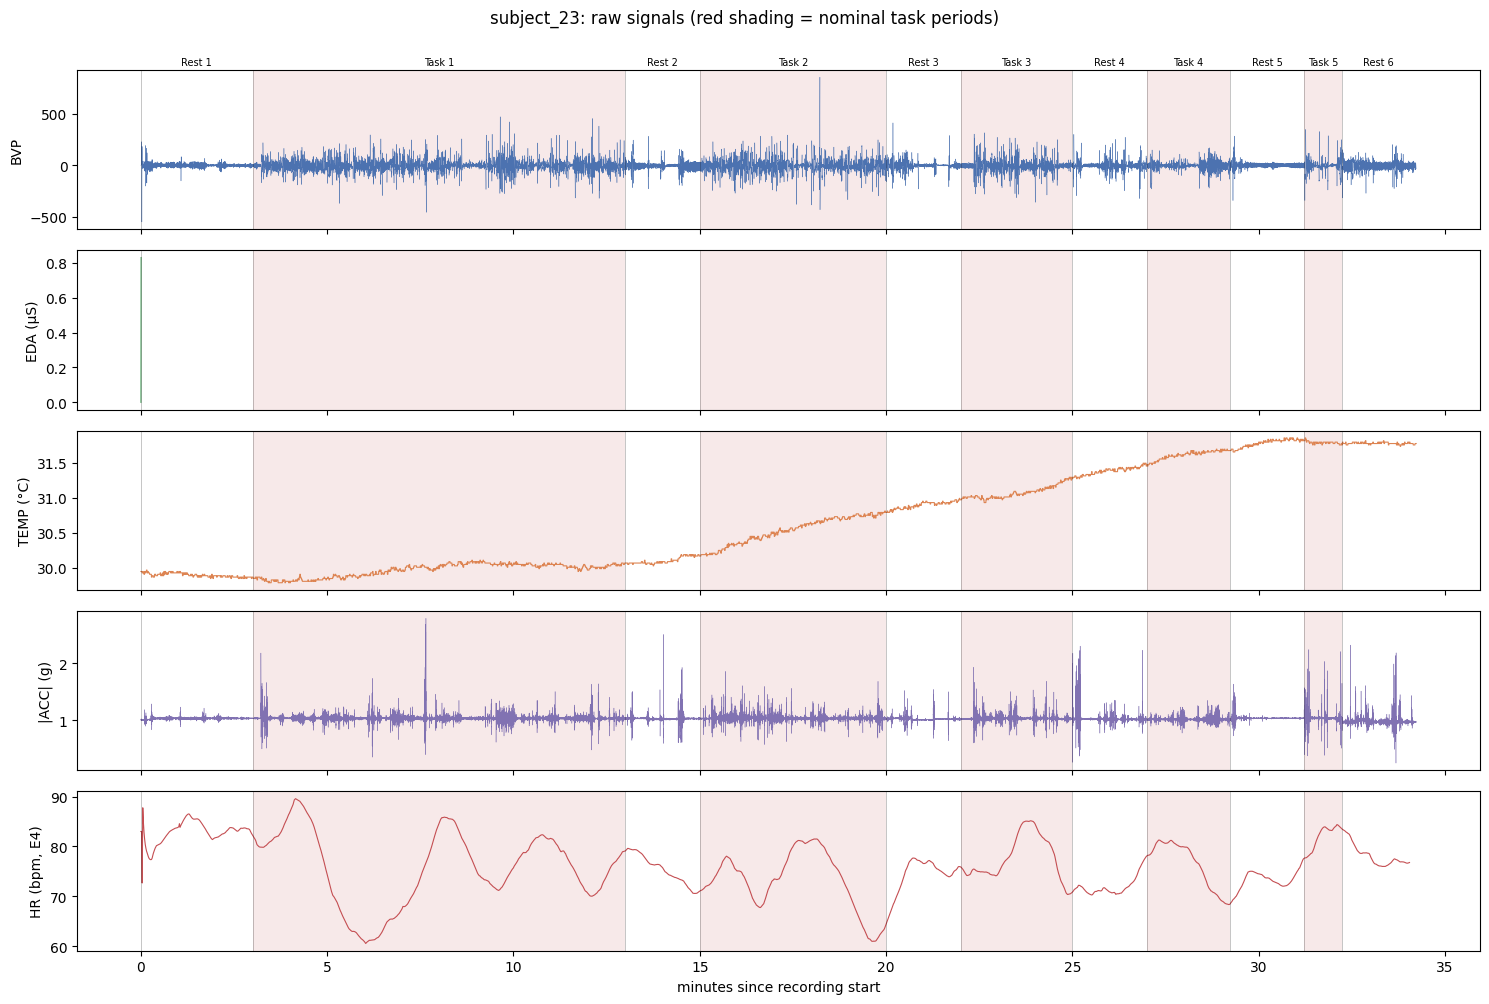

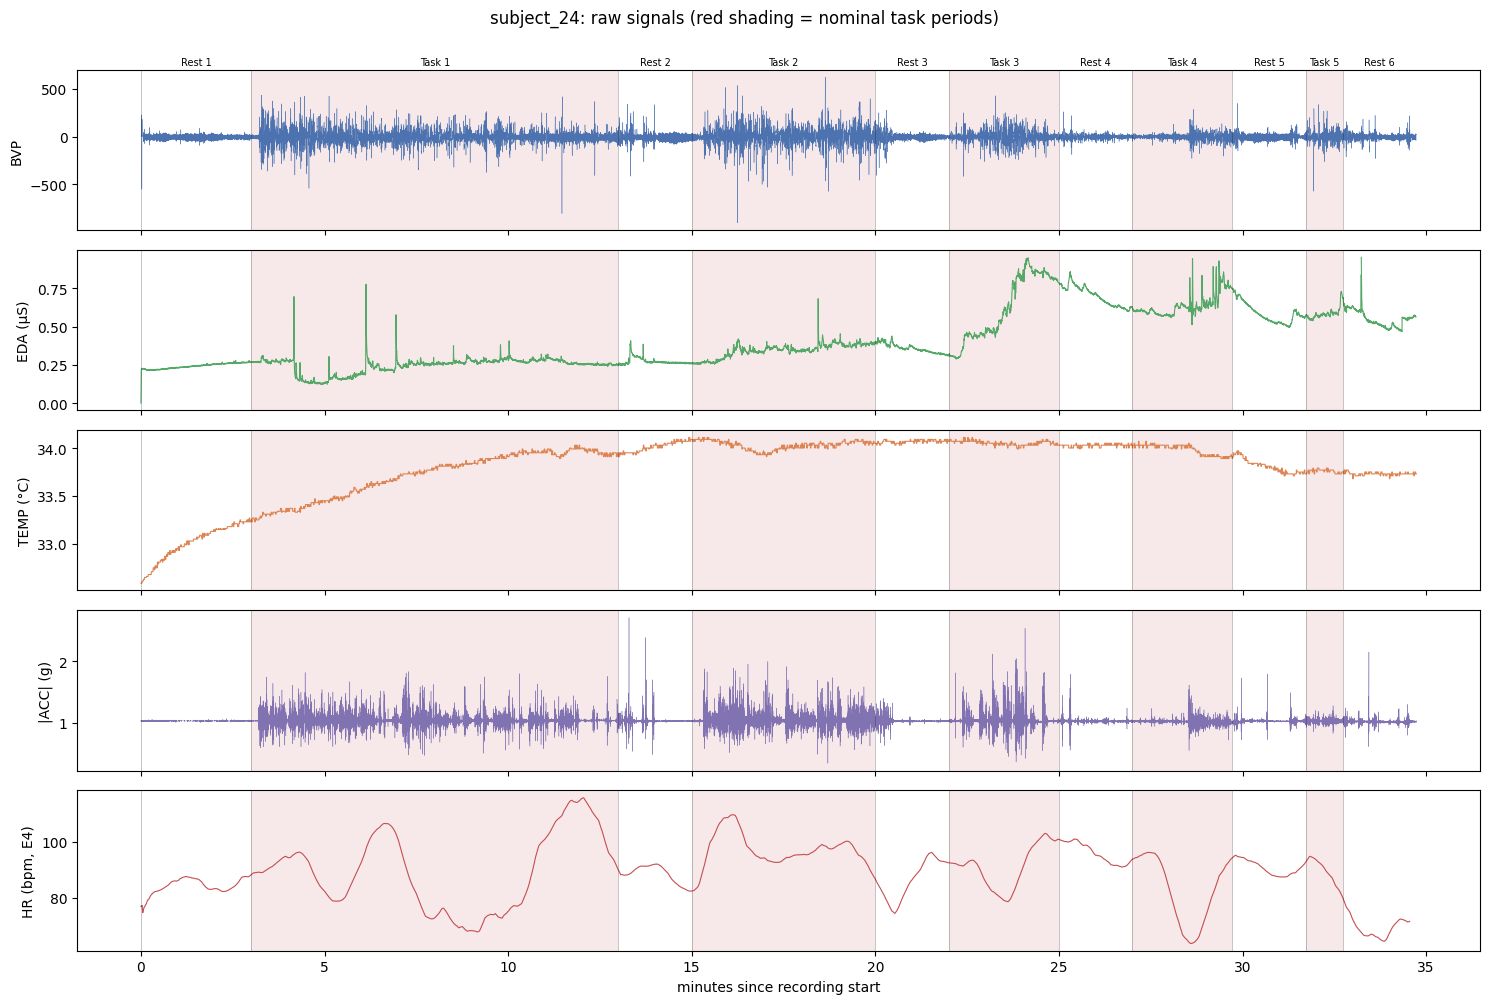

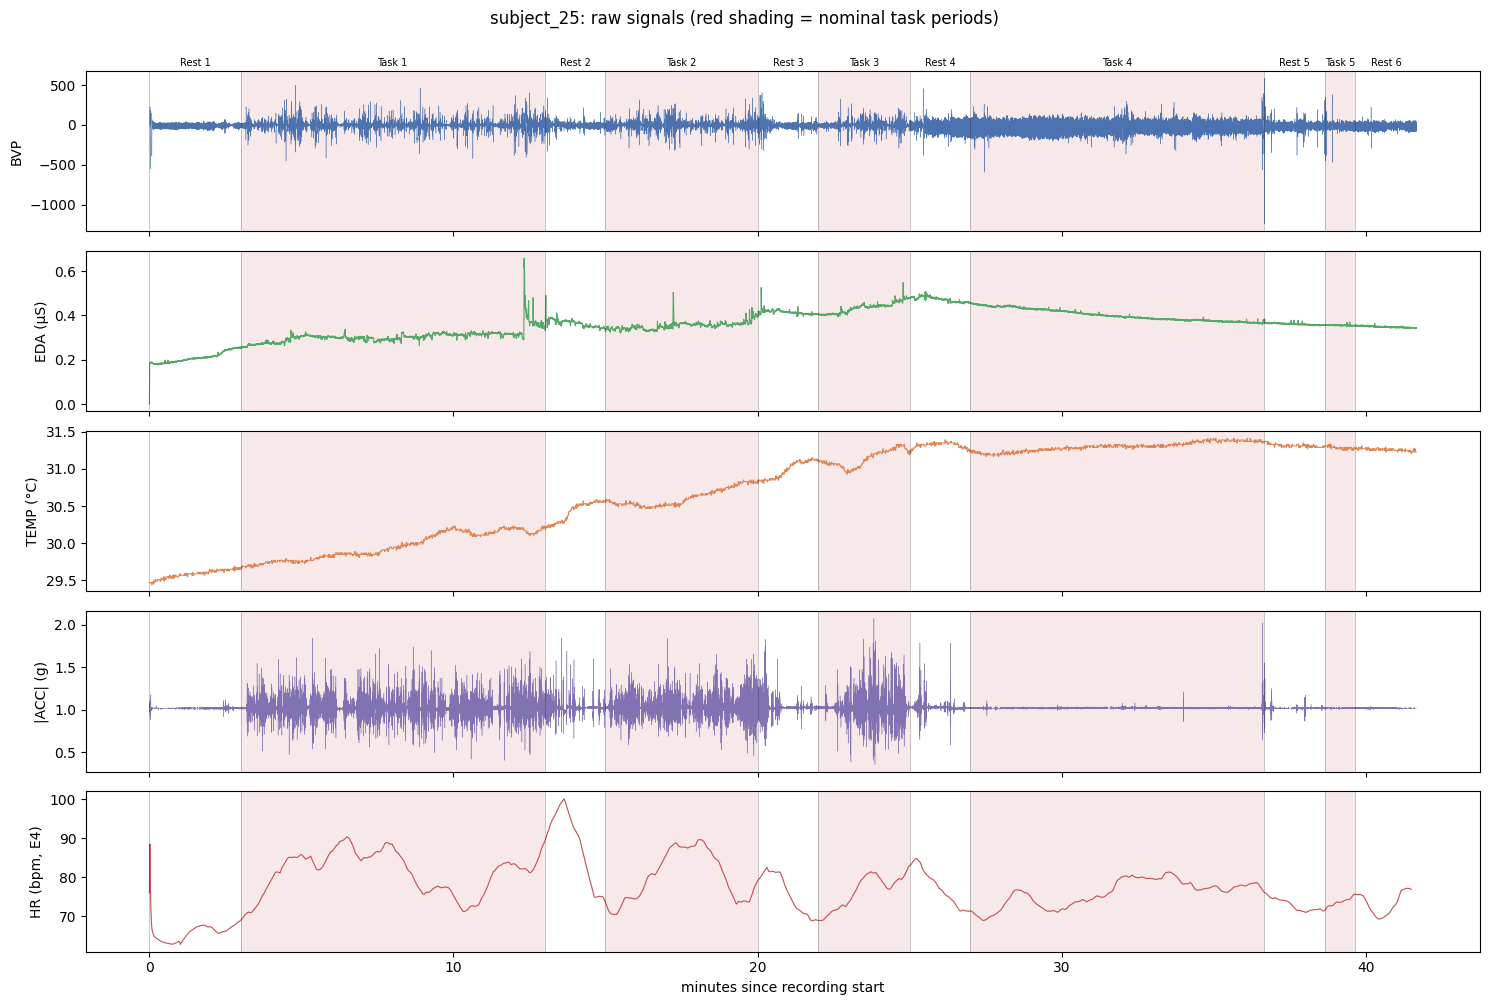

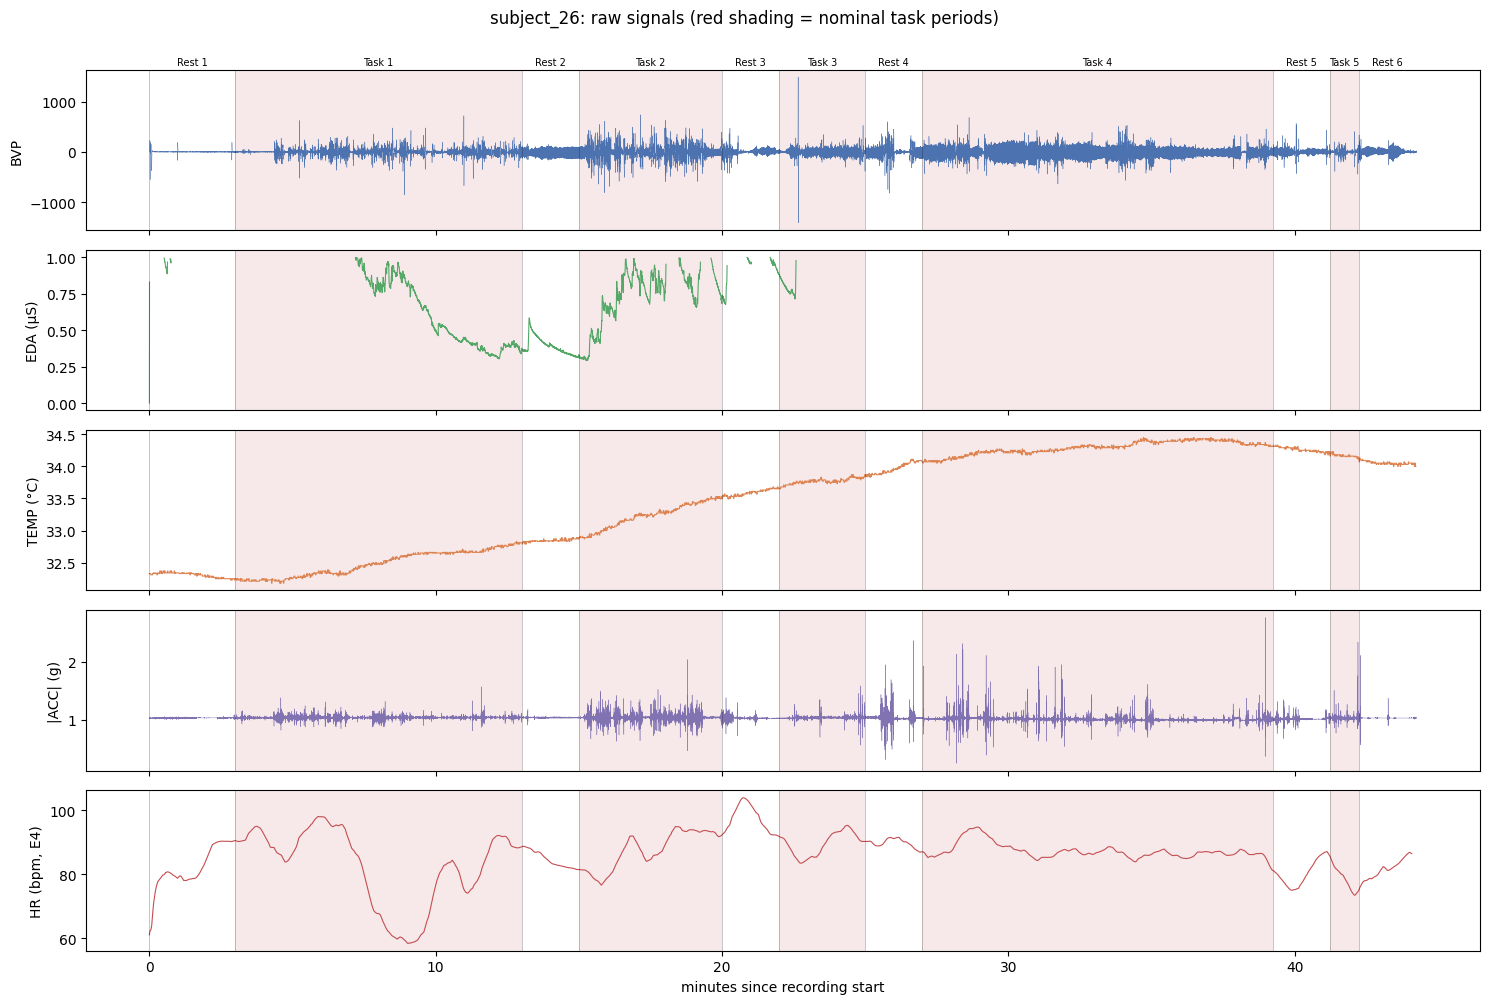

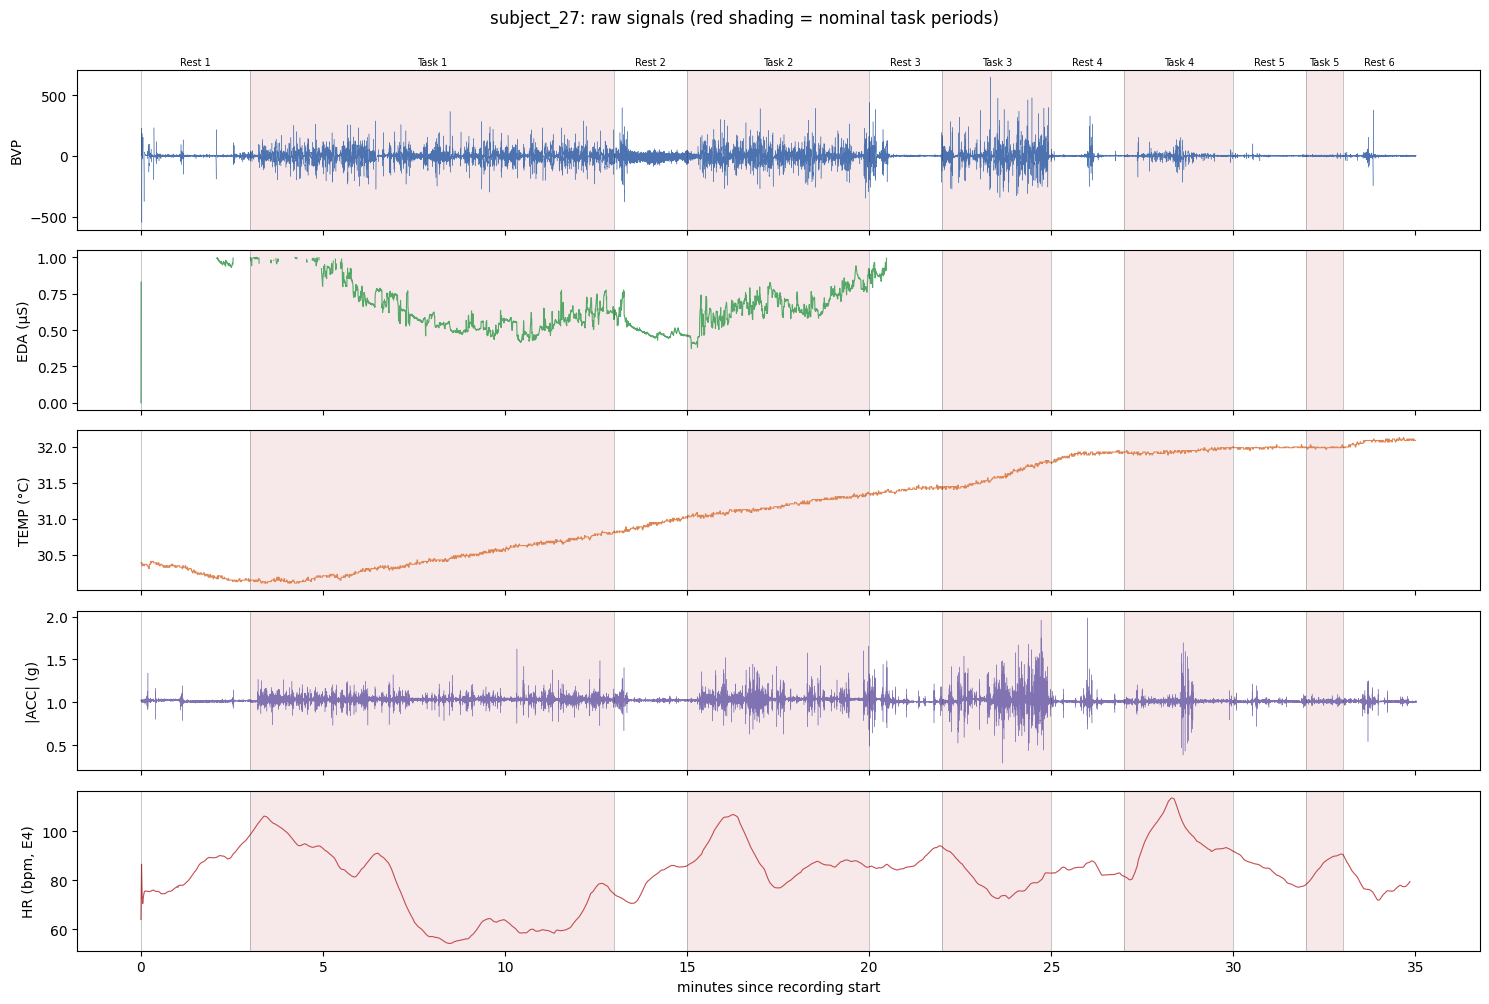

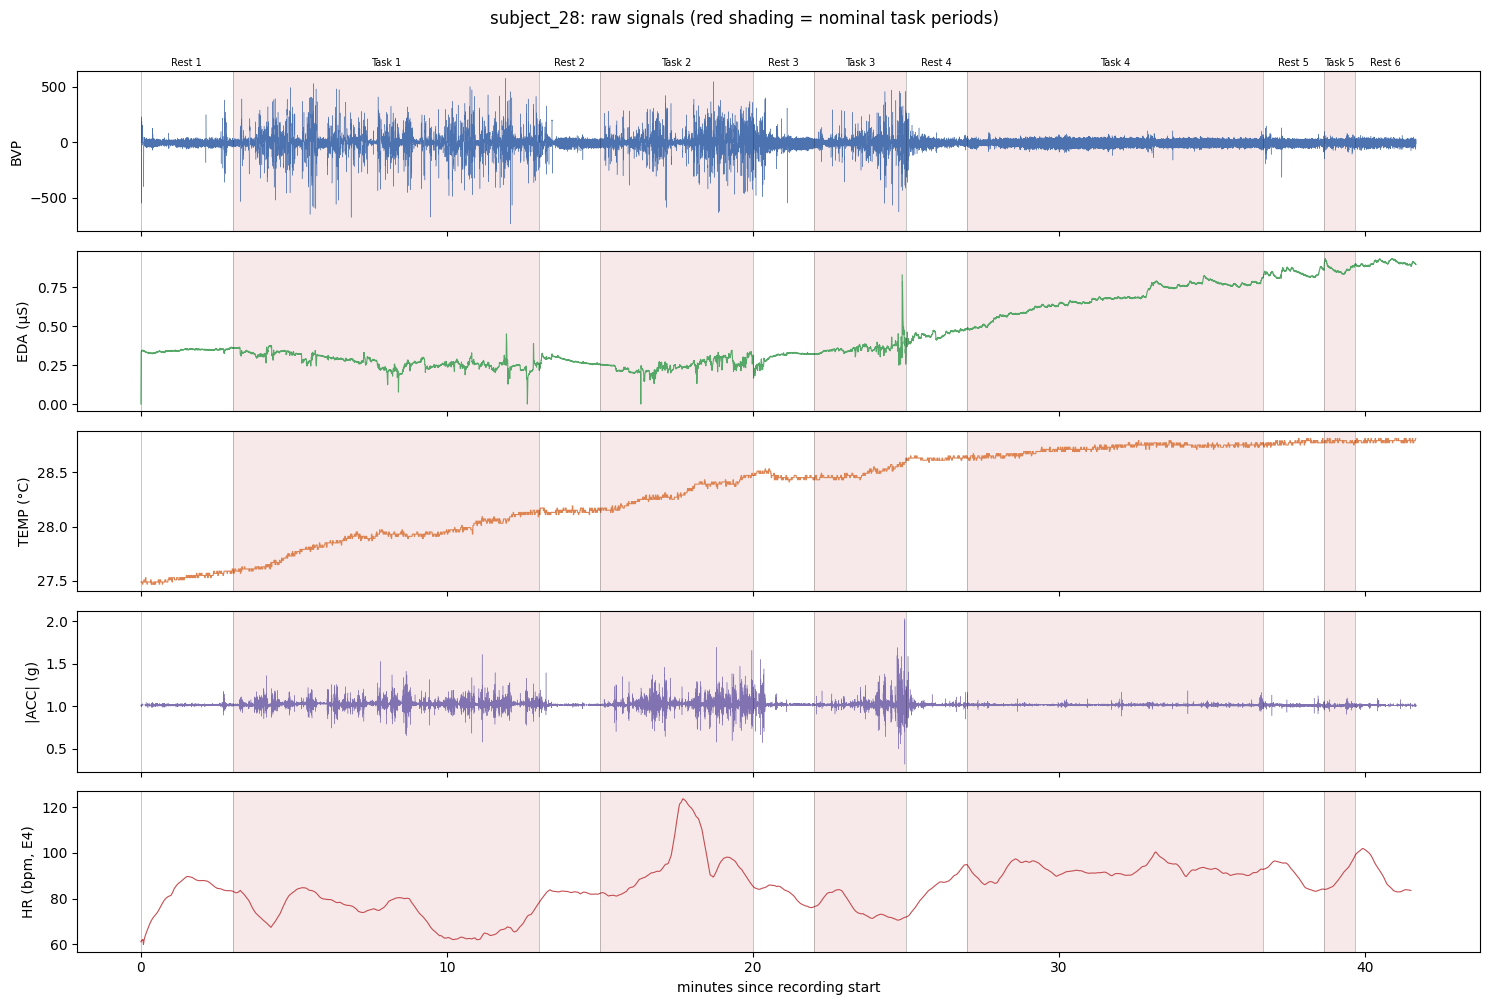

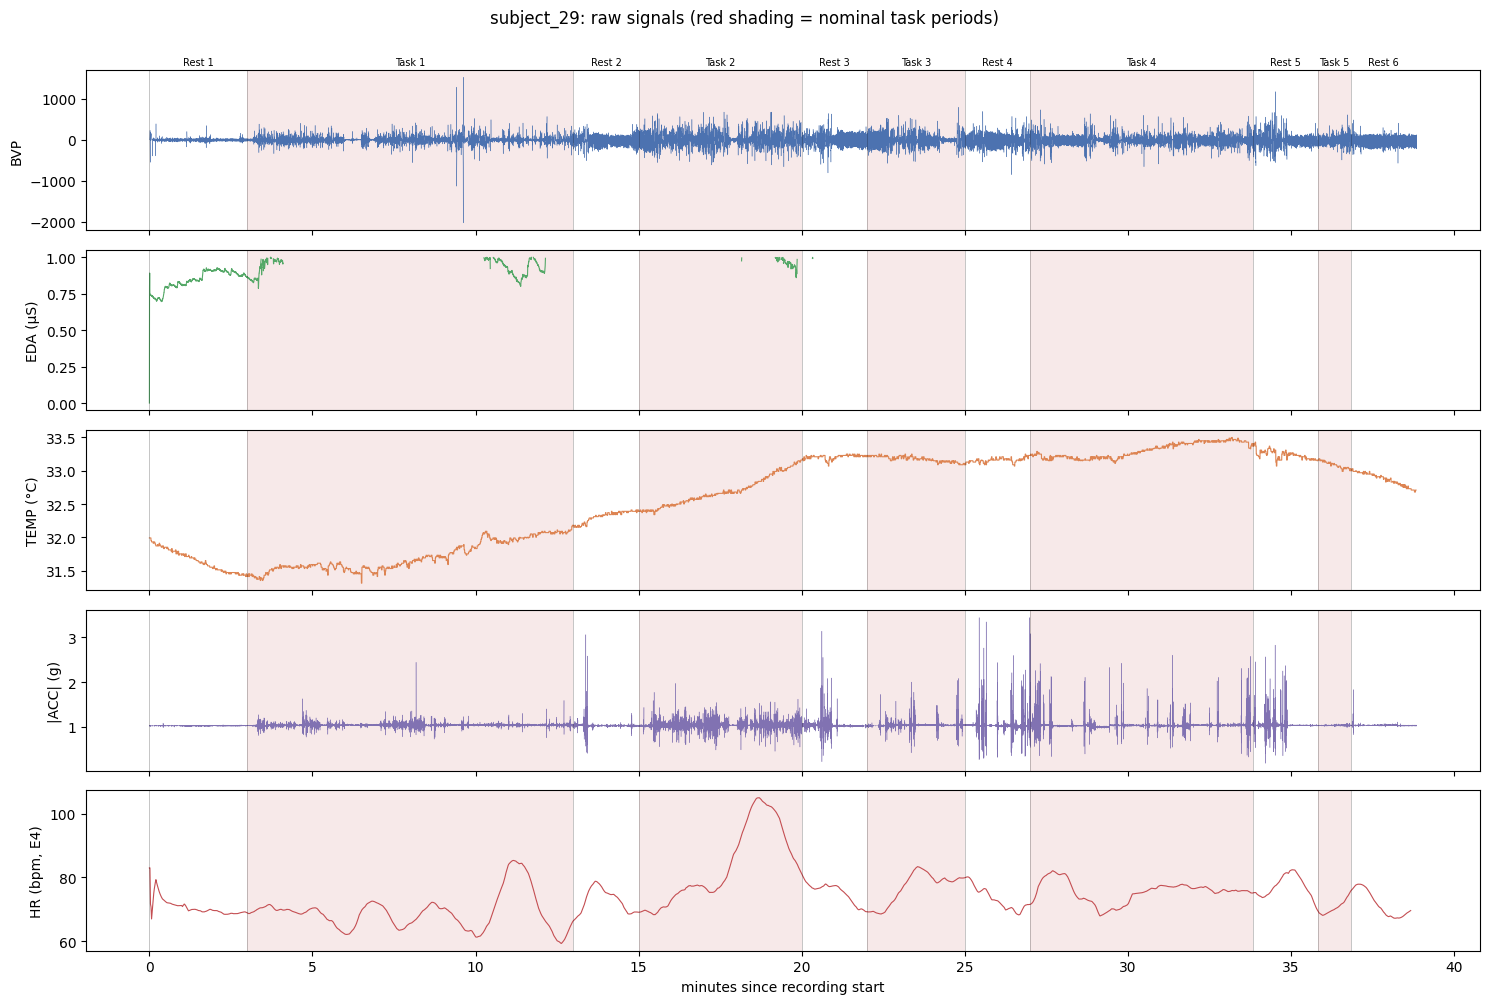

In [ ]:
for sid, s in dataset.items():
    fig = plot_session_overview(s)
    plt.show()
    plt.close(fig)  # free RAM

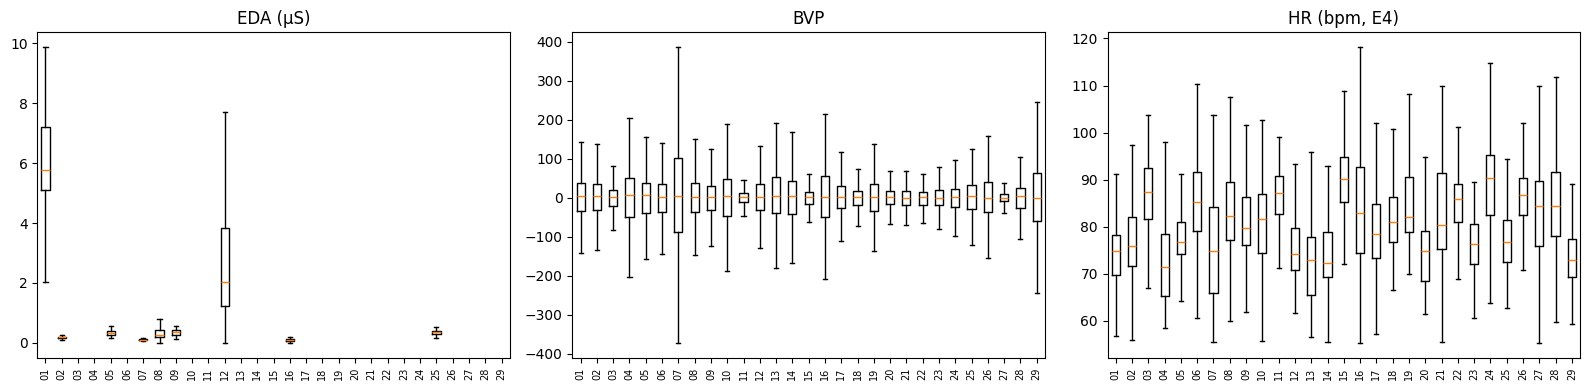

In [ ]:
def plot_signal_ranges(dataset):
    sids = list(dataset)
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    for ax, (name, title) in zip(axes, [("EDA", "EDA (µS)"), ("BVP", "BVP"), ("HR", "HR (bpm, E4)")]):
        data = [dataset[s]["signals"][name]["data"] for s in sids]
        ax.boxplot(data, showfliers=False)
        ax.set_xticks(range(1, len(sids) + 1))
        ax.set_xticklabels([s.split("_")[-1] for s in sids], rotation=90, fontsize=7)
        ax.set_title(title)
    fig.tight_layout()
    return fig


plot_signal_ranges(dataset)
plt.show()

In [ ]:
def count_missing_per_modality(dataset):
    """Counts missing (NaN) values for each sensor modality per subject."""
    rows = []
    for sid, s in dataset.items():
        sig = s["signals"]
        row = {"subject": sid}
        for sensor_name, sensor_data in sig.items():
            # Sum all NaN values in the sensor's data array
            nan_count = int(np.isnan(sensor_data["data"]).sum())
            row[sensor_name] = nan_count
        rows.append(row)

    df_missing = pd.DataFrame(rows).set_index("subject")

    # Fill with NA or 0 if a subject is entirely missing a specific sensor file
    df_missing = df_missing.fillna('Missing File')
    return df_missing

# Assuming 'dataset' is already loaded in your environment:
missing_counts_df = count_missing_per_modality(dataset)
display(missing_counts_df)

,BVP,EDA,TEMP,ACC,HR,IBI
subject,,,,,,
subject_01,0,0,0,0,0,0
subject_02,0,0,0,0,0,0
subject_03,0,4222,0,0,0,0
subject_04,0,1763,0,0,0,0
subject_05,0,0,0,0,0,0
subject_06,0,4965,0,0,0,0
subject_07,0,0,0,0,0,0
subject_08,0,0,0,0,0,0
subject_09,0,0,0,0,0,0


#**Preprocessing**
What the paper does, and what I changed:

| Step | Paper | Here |
|---|---|---|
| Segmentation | 1-min windows inside each protocol segment | same, but `step_sec` is a parameter (60 = paper; the WESAD loader used 60/15) |
| BVP filter | Chebyshev II, order 4, 20 dB, 0.5–5 Hz, applied per 1-min segment | same filter, applied **to the whole recording, zero-phase** (`sosfiltfilt`), then windowed → no edge transients inside windows |
| Beat detection | `findpeaks`, min distance 0.4 s, min height 0 | same (`find_peaks`) |
| Beat QC | keep intervals in 500–1200 ms; drop window if > 15 % abnormal | same |
| EDA | upsample 4→64 Hz, Gaussian smoothing (40-pt window, σ = 400 ms) | same available; default keeps native 4 Hz (upsampling adds no information, it only matched BVP's rate) |
| Normalisation | z-score of the *features* (population-wide) | **per-subject, on Rest 1** (as in WESAD), with the first `trim_start_sec` of Rest 1 excluded |

Notes: (a) in scipy `cheby2` the edges are the *stopband* edges; the paper says "passband 0.5–5 Hz", so the exact MATLAB parametrisation is ambiguous. (b) The paper does not say its 10-fold CV was grouped by subject; with windows from the same person in train and validation, scores are probably optimistic. Use subject-wise splits (e.g. `GroupKFold`) when you train.

In [ ]:
BVP_FS = 64


def filter_bvp(x, fs=BVP_FS, order=4, rs=20, band=(0.5, 5.0)):
    """Chebyshev II band-pass as in the paper, zero-phase."""
    sos = signal.cheby2(order, rs, band, btype="bandpass", fs=fs, output="sos")
    return signal.sosfiltfilt(sos, x)


def get_bvp_filtered(subj):
    if "_bvp_filt" not in subj:
        subj["_bvp_filt"] = filter_bvp(subj["signals"]["BVP"]["data"])
    return subj["_bvp_filt"]


def detect_beats(x_filt, fs=BVP_FS, min_dist_s=0.4, pp_min_ms=500, pp_max_ms=1200):
    """Peaks, peak-to-peak intervals (ms) and a boolean 'abnormal' flag per interval."""
    peaks, _ = find_peaks(x_filt, distance=int(min_dist_s * fs), height=0)
    pp = np.diff(peaks) / fs * 1000.0
    abnormal = (pp < pp_min_ms) | (pp > pp_max_ms)
    return peaks, pp, abnormal


def smooth_eda(x, fs=4, upsample_to=None, win=40, sigma_s=0.4):
    """Optional paper-style EDA cleaning. upsample_to=64 reproduces the paper exactly
    (linear interpolation, then Gaussian window of `win` points with sigma = sigma_s seconds).
    With upsample_to=None a gentle Gaussian is applied at the native rate."""
    if upsample_to:
        t = np.arange(len(x)) / fs
        t_new = np.arange(0, t[-1], 1 / upsample_to)
        x = np.interp(t_new, t, x)
        fs = upsample_to
        win_pts = win
    else:
        win_pts = max(3, int(round(win / 64 * fs)) | 1)  # ~0.6 s window
    g = signal.windows.gaussian(win_pts, std=sigma_s * fs)
    g /= g.sum()
    return np.convolve(x, g, mode="same"), fs


def eda_qc(x, fs=4, lo=0.05, hi=60.0, max_slope=10.0):
    """Rule-based artifact fractions (common EDA heuristics: range 0.05-60 µS, |slope| < 10 µS/s)."""
    out_of_range = ((x < lo) | (x > hi)).mean()
    slope = np.abs(np.diff(x)) * fs
    return float(out_of_range), float((slope > max_slope).mean())

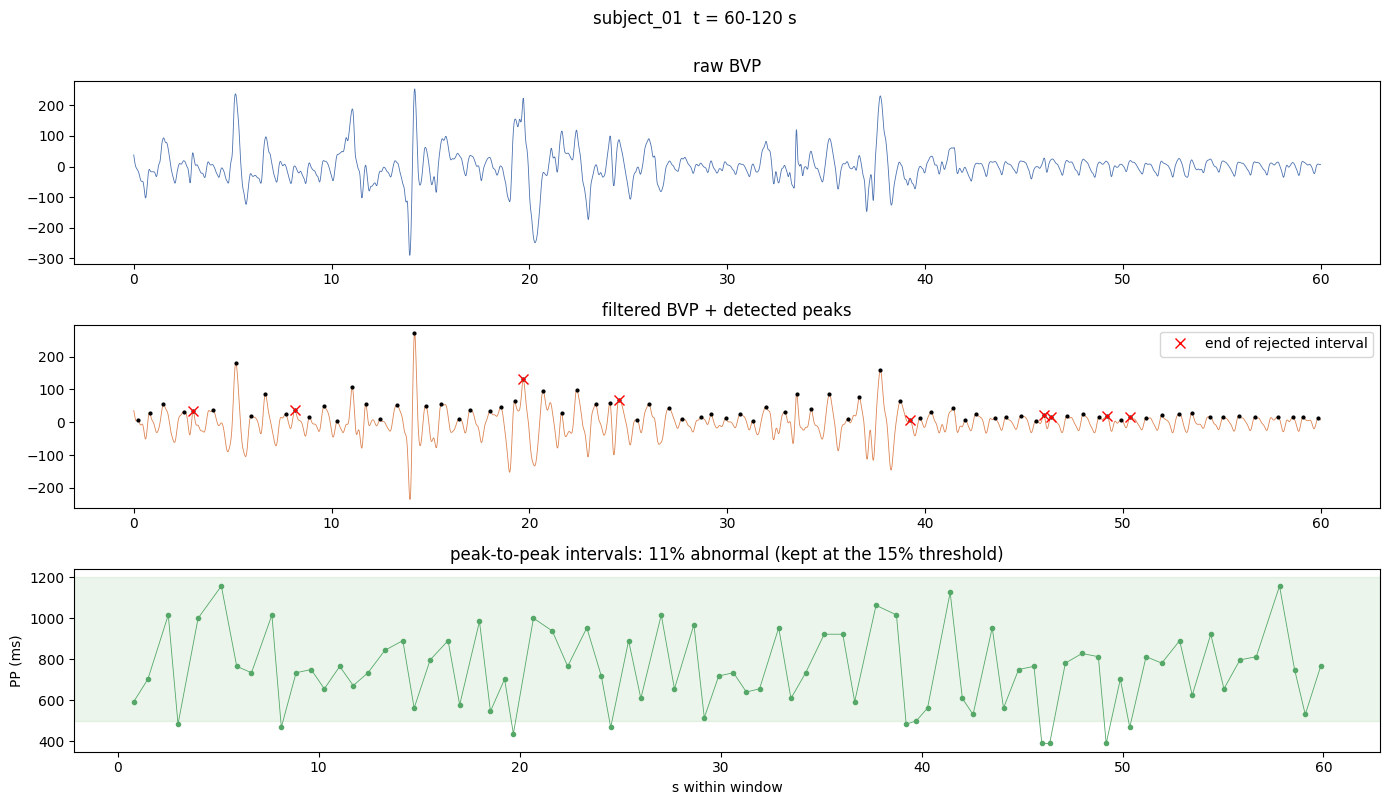

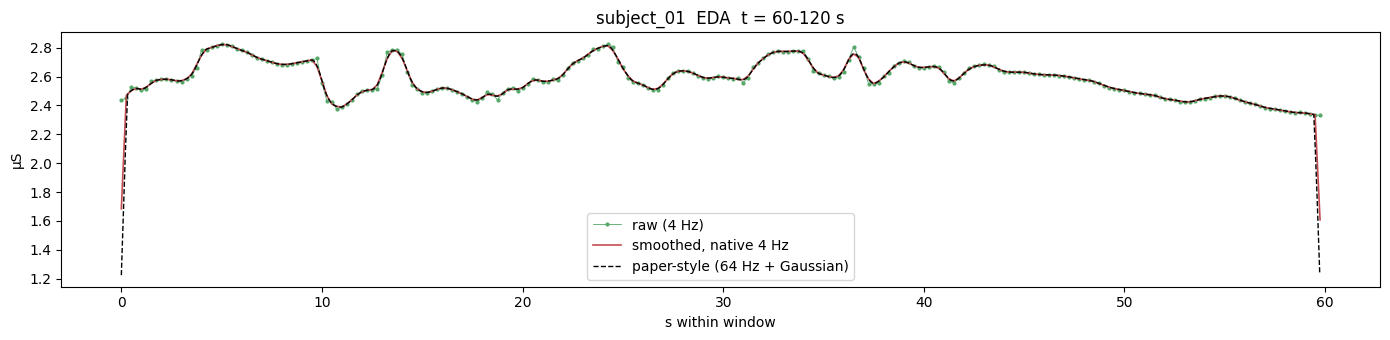

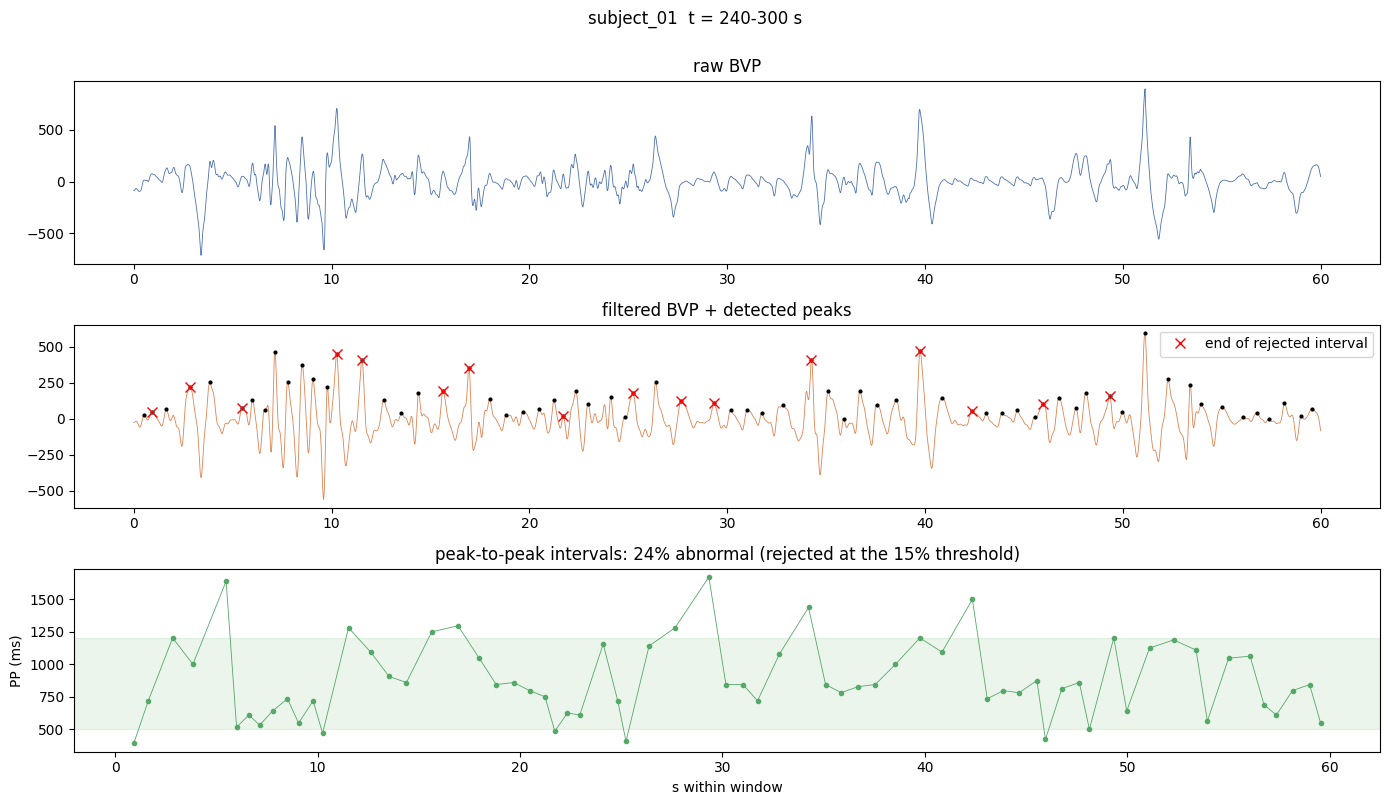

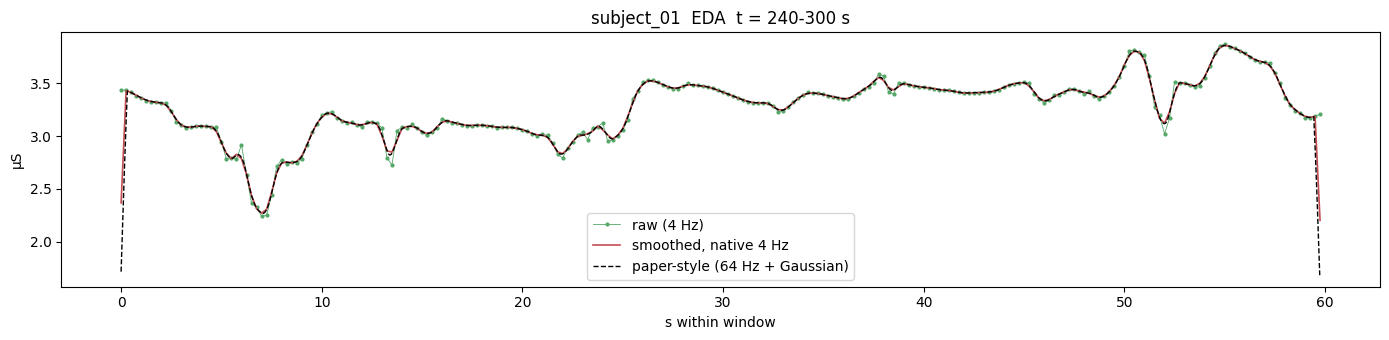

In [ ]:
def plot_bvp_window(subj, start_sec, win_sec=60):
    fs = BVP_FS
    a, b = int(start_sec * fs), int((start_sec + win_sec) * fs)
    raw = subj["signals"]["BVP"]["data"][a:b]
    filt = get_bvp_filtered(subj)[a:b]
    peaks, pp, abn = detect_beats(filt)
    t = np.arange(len(raw)) / fs

    fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=False)
    axes[0].plot(t, raw, lw=0.6, color="#4c72b0"); axes[0].set_title("raw BVP")
    axes[1].plot(t, filt, lw=0.6, color="#dd8452")
    axes[1].plot(t[peaks], filt[peaks], "k.", ms=4)
    bad_end = peaks[1:][abn] if len(pp) else np.array([], dtype=int)
    axes[1].plot(t[bad_end], filt[bad_end], "rx", ms=7, label="end of rejected interval")
    axes[1].set_title("filtered BVP + detected peaks"); axes[1].legend(loc="upper right")
    axes[2].plot(t[peaks[1:]], pp, "o-", ms=3, lw=0.6, color="#55a868")
    axes[2].axhspan(500, 1200, color="green", alpha=0.08)
    axes[2].set_ylabel("PP (ms)"); axes[2].set_xlabel("s within window")
    axes[2].set_title(f"peak-to-peak intervals: {abn.mean() * 100:.0f}% abnormal "
                      f"({'rejected' if abn.mean() > 0.15 else 'kept'} at the 15% threshold)")
    fig.suptitle(f"{subj['subject']}  t = {start_sec:.0f}-{start_sec + win_sec:.0f} s", y=1.0)
    fig.tight_layout()
    return fig


def plot_eda_window(subj, start_sec, win_sec=60):
    fs = 4
    a, b = int(start_sec * fs), int((start_sec + win_sec) * fs)
    raw = subj["signals"]["EDA"]["data"][a:b]
    sm_native, _ = smooth_eda(raw, fs)
    sm_paper, fs64 = smooth_eda(raw, fs, upsample_to=64)
    fig, ax = plt.subplots(figsize=(14, 3.5))
    ax.plot(np.arange(len(raw)) / fs, raw, "o-", ms=2, lw=0.6, label="raw (4 Hz)", color="#55a868")
    ax.plot(np.arange(len(sm_native)) / fs, sm_native, lw=1.2, label="smoothed, native 4 Hz", color="#c44e52")
    ax.plot(np.arange(len(sm_paper)) / fs64, sm_paper, lw=1.0, ls="--", label="paper-style (64 Hz + Gaussian)", color="k")
    ax.set_xlabel("s within window"); ax.set_ylabel("µS"); ax.legend()
    ax.set_title(f"{subj['subject']}  EDA  t = {start_sec:.0f}-{start_sec + win_sec:.0f} s")
    fig.tight_layout()
    return fig


s0 = dataset[sid0]
segs0 = nominal_schedule(session_duration(s0))
rest_start = segs0[0][1] + 60       # a minute inside Rest 1
task_start = segs0[1][1] + 60       # a minute inside Task 1 (Lego without instructions: lots of arm movement)
for st in (rest_start, task_start):
    plot_bvp_window(s0, st); plt.show()
    plot_eda_window(s0, st); plt.show()

In [ ]:
def baseline_stats(subj, segs, trim_start_sec=30):
    """Per-subject mean/std over Rest 1, skipping the first `trim_start_sec` seconds
    (device-donning transient, same artifact I found in WESAD wrist EDA; Rest 1 is only 180 s here,
    so the trim has to be much shorter than WESAD's 300 s). Inspect the Rest 1 part of the overview
    plots to pick a value."""
    name, a, b, _ = segs[0]
    assert name == "Rest 1"
    a = a + trim_start_sec
    sig = subj["signals"]
    eda, _ = smooth_eda(sig["EDA"]["data"], 4)
    eda = eda[int(a * 4):int(b * 4)]
    temp = sig["TEMP"]["data"][int(a * 4):int(b * 4)]
    bvp = get_bvp_filtered(subj)[int(a * BVP_FS):int(b * BVP_FS)]
    eps = 1e-3  # floor so a very quiet baseline cannot blow the z-scores up
    return {"EDA": (eda.mean(), max(eda.std(), eps)),
            "TEMP": (temp.mean(), max(temp.std(), eps)),
            "BVP": (0.0, max(bvp.std(), eps))}  # filtered BVP is zero-mean: only scale it


def make_windows(subj, win_sec=60, step_sec=60, trim_start_sec=30, keep_arrays=True):
    """Slide a window inside each protocol segment (never across a boundary).
    Each window gets scalar QC/summary values and, optionally, the baseline-normalised signal slices."""
    segs = nominal_schedule(session_duration(subj))
    if segs is None:
        print(f"  [skip] {subj['subject']}: recording too short for the protocol")
        return []
    st = baseline_stats(subj, segs, trim_start_sec)
    sig = subj["signals"]
    bvp_f = get_bvp_filtered(subj)
    eda_s, _ = smooth_eda(sig["EDA"]["data"], 4)
    temp = sig["TEMP"]["data"]
    acc = sig["ACC"]["data"]
    acc_mag = acc_magnitude_g(acc)
    hr_t = time_axis(subj, "HR") if "HR" in sig else None

    out = []
    for seg_name, seg_a, seg_b, lab in segs:
        w = seg_a
        while w + win_sec <= seg_b + 1e-9:
            ba, bb = int(w * 64), int((w + win_sec) * 64)
            ea, eb = int(w * 4), int((w + win_sec) * 4)
            aa, ab = int(w * 32), int((w + win_sec) * 32)

            peaks, pp, abn = detect_beats(bvp_f[ba:bb])
            valid = pp[~abn]
            eda_oor, eda_slope = eda_qc(sig["EDA"]["data"][ea:eb])
            hr_csv = np.nan
            if hr_t is not None:
                m = (hr_t >= w) & (hr_t < w + win_sec)
                hr_csv = float(np.nanmean(sig["HR"]["data"][m])) if m.any() else np.nan

            row = {
                "subject": subj["subject"], "segment": seg_name, "label": lab,
                "t_start": w, "t_end": w + win_sec,
                "n_peaks": len(peaks),
                "bvp_abn_frac": float(abn.mean()) if len(pp) else 1.0,
                "hr_bvp": float((60000.0 / valid).mean()) if len(valid) else np.nan,
                "hr_csv": hr_csv,
                "eda_mean_raw": float(eda_s[ea:eb].mean()),
                "eda_mean_norm": float(((eda_s[ea:eb] - st["EDA"][0]) / st["EDA"][1]).mean()),
                "temp_mean_raw": float(temp[ea:eb].mean()),
                "temp_mean_norm": float(((temp[ea:eb] - st["TEMP"][0]) / st["TEMP"][1]).mean()),
                "eda_out_of_range": eda_oor, "eda_fast_slope": eda_slope,
                "acc_std": float(acc_mag[aa:ab].std()),
            }
            if keep_arrays:
                row["x"] = {
                    "BVP": bvp_f[ba:bb] / st["BVP"][1],
                    "EDA": (eda_s[ea:eb] - st["EDA"][0]) / st["EDA"][1],
                    "TEMP": (temp[ea:eb] - st["TEMP"][0]) / st["TEMP"][1],
                    "ACC": acc[aa:ab] / 64.0,
                }
            out.append(row)
            w += step_sec
    return out


def build_dataset(dataset, win_sec=60, step_sec=60, trim_start_sec=30, keep_arrays=True):
    windows = []
    for sid, subj in dataset.items():
        ws = make_windows(subj, win_sec, step_sec, trim_start_sec, keep_arrays)
        windows.extend(ws)
        print(f"  {sid}: {len(ws)} windows")
    print(f"Total: {len(windows)} windows across {len(dataset)} subjects")
    return windows


windows = build_dataset(dataset)  # paper setting: non-overlapping 60 s
df = pd.DataFrame([{k: v for k, v in w.items() if k != "x"} for w in windows])
df["keep"] = df["bvp_abn_frac"] <= 0.15   # paper's PPG rule
df.groupby("label")["keep"].agg(total="size", kept="sum")

  subject_01: 41 windows
  subject_02: 39 windows
  subject_03: 34 windows
  subject_04: 35 windows
  subject_05: 34 windows
  subject_06: 36 windows
  subject_07: 35 windows
  subject_08: 37 windows
  subject_09: 37 windows
  subject_10: 36 windows
  subject_11: 35 windows
  subject_12: 37 windows
  subject_13: 36 windows
  subject_14: 43 windows
  subject_15: 38 windows
  subject_16: 35 windows
  subject_17: 39 windows
  subject_18: 35 windows
  subject_19: 35 windows
  subject_20: 35 windows
  subject_21: 36 windows
  subject_22: 34 windows
  subject_23: 34 windows
  subject_24: 34 windows
  subject_25: 41 windows
  subject_26: 44 windows
  subject_27: 35 windows
  subject_28: 41 windows
  subject_29: 38 windows
Total: 1069 windows across 29 subjects


,total,kept
label,,
0,377,250
1,692,280


#**Visualizing preprocessing effects**

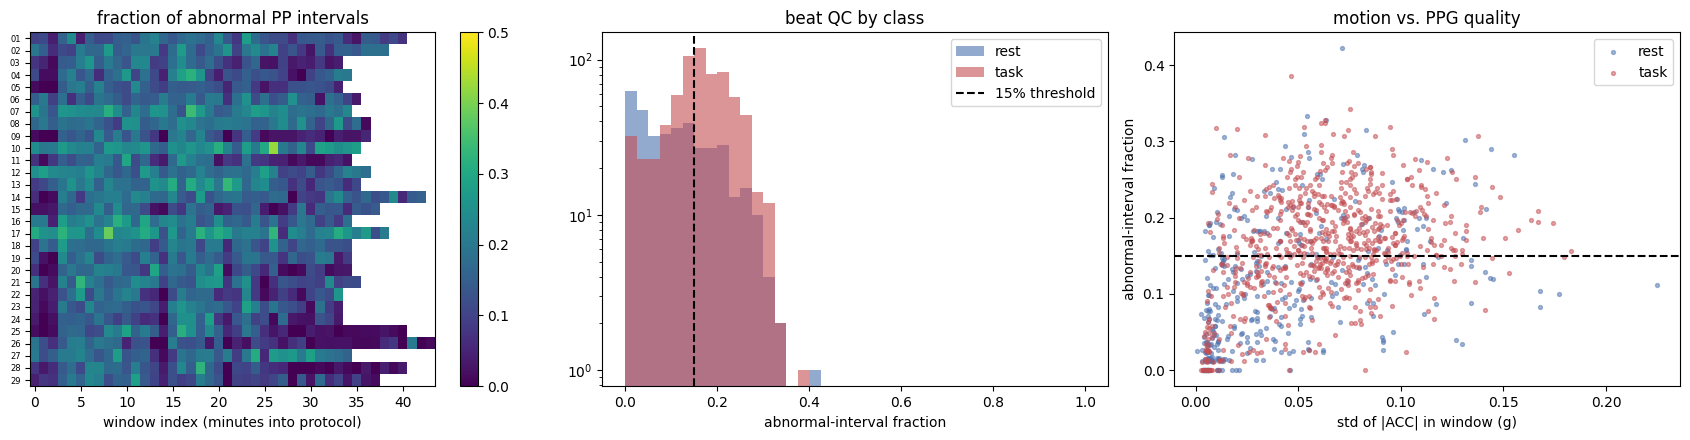

In [ ]:
def plot_window_qc(df):
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

    # 1) which windows fail beat-QC, per subject over time
    df = df.copy()
    df["w_idx"] = df.groupby("subject").cumcount()
    piv = df.pivot(index="subject", columns="w_idx", values="bvp_abn_frac")
    im = axes[0].imshow(piv.values, aspect="auto", cmap="viridis", vmin=0, vmax=0.5)
    axes[0].set_yticks(range(len(piv))); axes[0].set_yticklabels([s.split("_")[-1] for s in piv.index], fontsize=6)
    axes[0].set_xlabel("window index (minutes into protocol)"); axes[0].set_title("fraction of abnormal PP intervals")
    fig.colorbar(im, ax=axes[0])

    # 2) distribution by class with the paper's 15% threshold
    bins = np.linspace(0, 1, 41)
    for lab, c, n in [(0, "#4c72b0", "rest"), (1, "#c44e52", "task")]:
        axes[1].hist(df[df.label == lab]["bvp_abn_frac"], bins=bins, alpha=0.6, color=c, label=n)
    axes[1].axvline(0.15, color="k", ls="--", label="15% threshold")
    axes[1].set_xlabel("abnormal-interval fraction"); axes[1].set_yscale("log"); axes[1].legend()
    axes[1].set_title("beat QC by class")

    # 3) motion vs beat QC
    for lab, c, n in [(0, "#4c72b0", "rest"), (1, "#c44e52", "task")]:
        d = df[df.label == lab]
        axes[2].scatter(d["acc_std"], d["bvp_abn_frac"], s=8, alpha=0.5, color=c, label=n)
    axes[2].axhline(0.15, color="k", ls="--")
    axes[2].set_xlabel("std of |ACC| in window (g)"); axes[2].set_ylabel("abnormal-interval fraction")
    axes[2].set_title("motion vs. PPG quality"); axes[2].legend()
    fig.tight_layout()
    return fig


plot_window_qc(df)
plt.show()

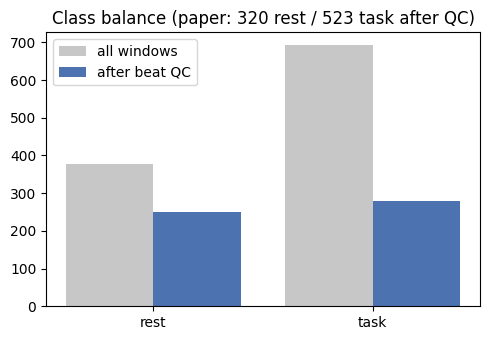

In [ ]:
def plot_class_balance(df):
    g = df.groupby("label")["keep"].agg(total="size", kept="sum")
    fig, ax = plt.subplots(figsize=(5, 3.5))
    x = np.arange(2)
    ax.bar(x - 0.2, g["total"], 0.4, label="all windows", color="#c7c7c7")
    ax.bar(x + 0.2, g["kept"], 0.4, label="after beat QC", color="#4c72b0")
    ax.set_xticks(x); ax.set_xticklabels(["rest", "task"]); ax.legend()
    ax.set_title("Class balance (paper: 320 rest / 523 task after QC)")
    fig.tight_layout()
    return fig


plot_class_balance(df)
plt.show()

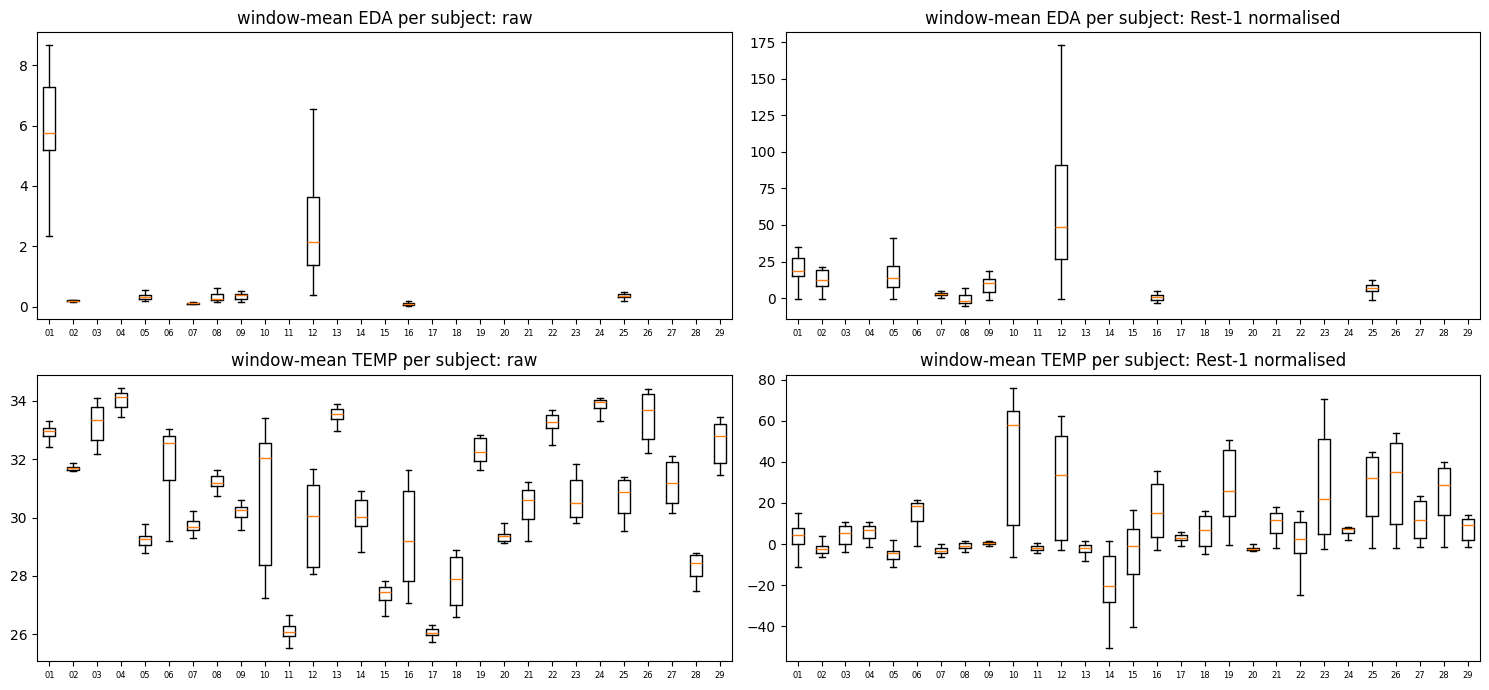

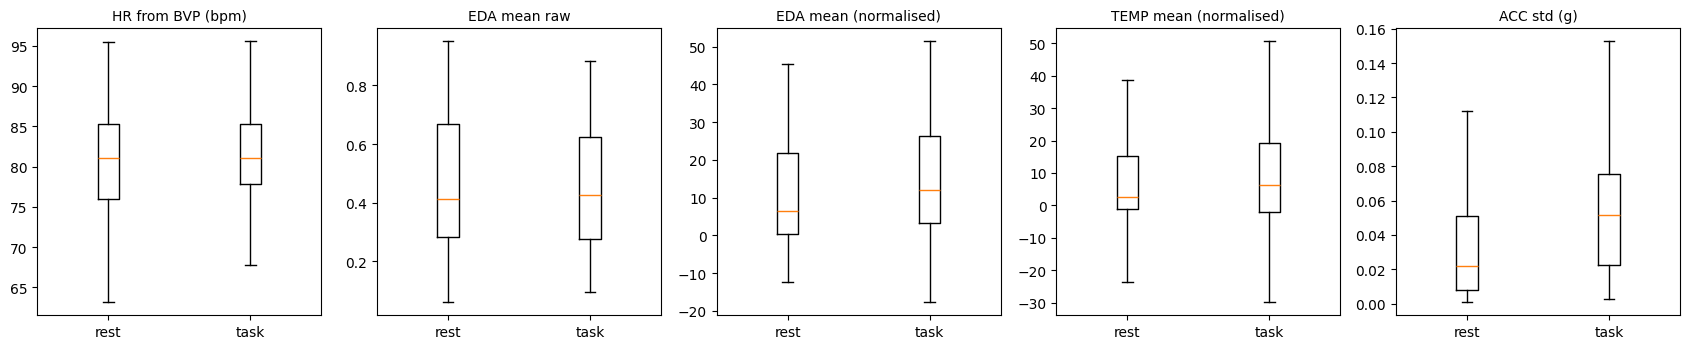

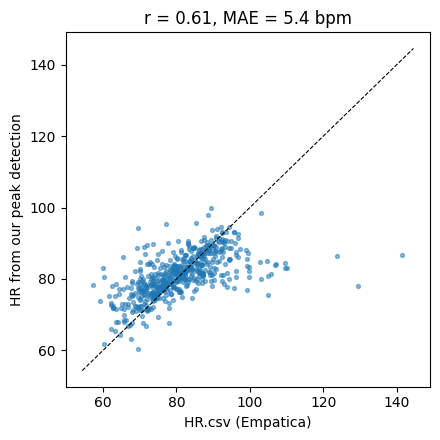

In [ ]:
def plot_normalization_effect(df):
    sids = sorted(df.subject.unique())
    fig, axes = plt.subplots(2, 2, figsize=(15, 7))
    for j, (col, title) in enumerate([("eda_mean", "window-mean EDA"), ("temp_mean", "window-mean TEMP")]):
        for i, suffix in enumerate(["raw", "norm"]):
            ax = axes[j, i]
            ax.boxplot([df[df.subject == s][f"{col}_{suffix}"] for s in sids], showfliers=False)
            ax.set_xticks(range(1, len(sids) + 1)); ax.set_xticklabels([s.split("_")[-1] for s in sids], fontsize=6)
            ax.set_title(f"{title} per subject: {'raw' if suffix == 'raw' else 'Rest-1 normalised'}")
    fig.tight_layout()
    return fig


def plot_class_separability(df):
    d = df[df.keep]
    cols = [("hr_bvp", "HR from BVP (bpm)"), ("eda_mean_raw", "EDA mean raw"), ("eda_mean_norm", "EDA mean (normalised)"),
            ("temp_mean_norm", "TEMP mean (normalised)"), ("acc_std", "ACC std (g)")]
    fig, axes = plt.subplots(1, len(cols), figsize=(17, 3.6))
    for ax, (c, t) in zip(axes, cols):
        ax.boxplot([d[d.label == 0][c].dropna(), d[d.label == 1][c].dropna()], showfliers=False)
        ax.set_xticks([1, 2]); ax.set_xticklabels(["rest", "task"]); ax.set_title(t, fontsize=10)
    fig.tight_layout()
    return fig


def plot_hr_agreement(df):
    d = df[df.keep].dropna(subset=["hr_bvp", "hr_csv"])
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    ax.scatter(d["hr_csv"], d["hr_bvp"], s=8, alpha=0.5)
    lim = [d[["hr_csv", "hr_bvp"]].min().min() - 3, d[["hr_csv", "hr_bvp"]].max().max() + 3]
    ax.plot(lim, lim, "k--", lw=0.8)
    ax.set_xlabel("HR.csv (Empatica)"); ax.set_ylabel("HR from our peak detection")
    mae = (d["hr_csv"] - d["hr_bvp"]).abs().mean()
    ax.set_title(f"r = {d['hr_csv'].corr(d['hr_bvp']):.2f}, MAE = {mae:.1f} bpm")
    fig.tight_layout()
    return fig


plot_normalization_effect(df); plt.show()
plot_class_separability(df); plt.show()
plot_hr_agreement(df); plt.show()